# GlowUp Radar · Entrega final: segunda vuelta de CRISP-DM y despliegue

**Cliente:** Seoru, marca coreana de cuidado de la piel (sérums, limpiadores y protectores solares). **Pregunta:** ¿con qué importadores colombianos negociar para entrar en 2027?

**Integrantes:** Martín Noval Namen (202420760), Juan Camilo González (202215202), Mateo Pava (201822922), Juan Esteban Cómbita (202315452)

### Cómo está organizado

| Parte | Fase de CRISP-DM | Qué hacemos |
|---|---|---|
| 1–3 | Negocio y datos (vuelta 1, corregida) | Cargar, filtrar, revisar fuga y construir variables, con los ajustes que pidió el monitor |
| 4 | Preparación | Todo el preprocesamiento va dentro de un `Pipeline`, para que nada se aprenda por fuera de cada pliegue |
| 5–6 | Modelado y evaluación | Regla simple, logística, árbol, bosque aleatorio y XGBoost con la misma validación anidada y el mismo costo; prueba en 2024 una sola vez; sensibilidad a los costos |
| 7 | Evaluación | En qué se apoya el modelo (permutación y SHAP) y dónde se equivoca |
| 8 | Descubrimiento | Temas de producto sacados del texto de las notificaciones |
| 9–10 | Despliegue | Modelo final con 2023 y 2024, radar 2026, lista de 20 candidatos, valor frente a la regla y exportación a la app |

**Para correrlo:** suban `glowup_data.csv` (el de Bloque Neón) a una carpeta `GlowUp_Radar` en su Drive. Si también quieren exportar el modelo, pongan ahí la carpeta de la app. Después, *Entorno de ejecución → Ejecutar todas*. Se demora unos 10 minutos, casi todo en la sección 6.2.

## 1. Paquetes

In [ ]:
%pip install -q shap xgboost

In [ ]:
import glob
import json
import os
import re
import sys
import time
import unicodedata
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import NMF
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import PredefinedSplit, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
# colores que usamos en todos los gráficos (los mismos del informe)
AZUL, NARANJA, GRIS, VERDE = "#2a78d6", "#eb6834", "#9aa0a6", "#2e9e5b"

## 2. Configuración

Los costos son los del brief. Los dejamos en variables porque en la sección 6.6 los movemos para ver qué tan sensible es la recomendación.

In [ ]:
# rutas en Drive (si guardaron los archivos en otra carpeta, cámbienlas aquí)
RUTA_DATOS = "/content/drive/MyDrive/GlowUp_Radar/glowup_data.csv"
CARPETA_APP = "/content/drive/MyDrive/GlowUp_Radar/plantilla_app"
CARPETA_SALIDA = "resultados/"

# partición en el tiempo: entrenamos con 2023, probamos con 2024 y el radar es 2025
ANIO_ENT, ANIO_PRU, ANIO_RADAR = 2023, 2024, 2025
OBJETIVO = "y_abandona"
SEMILLA = 2559
K = 5          # pliegues
N_BOOT = 1000  # muestras para los intervalos

# costos del brief, en US$
COSTO_FIRMAR_ABANDONA = 250_000   # firmamos sin garantías y el importador abandona
COSTO_PERDER_BUENO = 50_000       # no firmamos con uno que sí habría funcionado
COSTO_GARANTIAS = 20_000          # las garantías cuestan esto siempre
PERDIDA_CON_GARANTIAS = 100_000   # lo que se pierde si abandona aunque haya garantías

os.makedirs(CARPETA_SALIDA, exist_ok=True)

def tabla_costos(perder_bueno=COSTO_PERDER_BUENO, garantias=COSTO_GARANTIAS):
    # costo de cada pareja (decisión, abandonó: 1 sí / 0 no)
    return {("firmar", 1): COSTO_FIRMAR_ABANDONA, ("firmar", 0): 0,
            ("garantias", 1): garantias + PERDIDA_CON_GARANTIAS, ("garantias", 0): garantias,
            ("no_firmar", 1): 0, ("no_firmar", 0): perder_bueno}

COSTOS = tabla_costos()
COSTOS

{('firmar', 1): 250000,
 ('firmar', 0): 0,
 ('garantias', 1): 120000,
 ('garantias', 0): 20000,
 ('no_firmar', 1): 0,
 ('no_firmar', 0): 50000}

## 3. Datos: carga, filtros, fuga y variables (vuelta 1, con las correcciones del monitor)
### 3.1 Cargar el archivo

Primero probamos la ruta de la sección 2. Si el archivo no está ahí, montamos Drive y lo buscamos por nombre (`glowup_data*.csv`).

In [ ]:
def encontrar_datos():
    # 1) la ruta de la sección 2 o un archivo subido directo a Colab (panel de archivos)
    for ruta in [RUTA_DATOS] + sorted(glob.glob("*glowup_data*.csv")):
        if os.path.exists(ruta):
            return ruta
    # 2) si no aparece, montamos Drive y lo buscamos
    if "google.colab" in sys.modules:
        from google.colab import drive
        drive.mount("/content/drive")
        if os.path.exists(RUTA_DATOS):
            return RUTA_DATOS
        encontrados = sorted(glob.glob("/content/drive/MyDrive/**/glowup_data*.csv", recursive=True))
        if encontrados:
            return encontrados[0]
    raise FileNotFoundError("No encontramos glowup_data.csv: revisen RUTA_DATOS en la sección 2.")

ARCHIVO = encontrar_datos()
crudos = pd.read_csv(ARCHIVO, encoding="utf-8-sig")
print("Archivo:", ARCHIVO, "| filas y columnas:", crudos.shape)
assert crudos.shape[1] == 55 and OBJETIVO in crudos.columns, "Este no es el archivo completo de 55 columnas"

Archivo: glowup_data-2.csv | filas y columnas: (1773, 55)


### 3.2 Filtros de la población (conteo antes y después)

Los mismos de la entrega 1: quitamos duplicados NIT-año, anonimizamos a las personas naturales (Ley 1581 de 2012) y dejamos solo a quienes venden cosmética de consumo, es decir, con notificaciones INVIMA o con actividad CIIU de cosméticos, farmacia o belleza.

In [ ]:
CIIU_CONSUMO = [202, 210, 461, 464, 469, 471, 475, 477, 479, 960]
conteo = []

def anotar(paso, tabla):
    fila = {"Paso": paso, "Filas": len(tabla)}
    for anio in [ANIO_ENT, ANIO_PRU, ANIO_RADAR]:
        fila[anio] = int((tabla["anio_t"] == anio).sum())
    fila["NIT distintos"] = int(tabla["nit"].nunique())
    fila["Filas sin NIT"] = int(tabla["nit"].isna().sum())
    conteo.append(fila)

datos = crudos.copy()
anotar("0. Archivo original", datos)
datos = datos.drop_duplicates(subset=["nit", "anio_t"], keep="first")
anotar("1. Sin duplicados NIT-año", datos)

# personas naturales: se anonimizan antes de cualquier otro paso
es_persona = datos["nit"].isna()
datos["importador"] = datos["razon_social"]
datos.loc[es_persona, "importador"] = "Persona natural (anónima)"
anotar("2. Personas naturales anonimizadas", datos)

en_poblacion = (datos["tiene_invima"] == 1) | datos["ciiu_2"].isin(CIIU_CONSUMO)
datos = datos[en_poblacion].copy()
anotar("3. Solo cosmética de consumo (INVIMA o CIIU)", datos)
tabla_filtros = pd.DataFrame(conteo)
tabla_filtros.to_csv(CARPETA_SALIDA + "tabla_filtros.csv", index=False)
print("Personas naturales que quedan después del filtro:", int(datos["nit"].isna().sum()))
tabla_filtros

Personas naturales que quedan después del filtro: 0


,Paso,Filas,2023,2024,2025,NIT distintos,Filas sin NIT
0,0. Archivo original,1773,574,578,621,790,3
1,1. Sin duplicados NIT-año,1773,574,578,621,790,3
2,2. Personas naturales anonimizadas,1773,574,578,621,790,3
3,3. Solo cosmética de consumo (INVIMA o CIIU),1484,477,484,523,663,0


**Qué queda.** 1.484 filas: 477 de 2023, 484 de 2024 y 523 de 2025. Las 3 filas de personas naturales se anonimizan, pero se caen en el filtro de población porque no tienen notificaciones INVIMA ni código CIIU, así que no hay cómo saber si venden cosmética. (En la entrega 1 la etiqueta de este paso decía "se conservan"; ya está corregida.)

### 3.3 Columnas que no entran al modelo

Seguimos el rol que les da el diccionario. Aquí atendemos dos comentarios del monitor: `n_grafias_razon` no entra y `tiene_invima` sale porque su rol es Contexto.

In [ ]:
EXCLUIDAS = {
    "cif_t1": "FUGA (diccionario): valor importado en t+1",
    "ratio_t1": "FUGA (diccionario): razón entre t+1 y t; con ella se arma el target",
    "y_abandona": "Es lo que se predice",
    "y_crece": "Target alterno; describe t+1",
    "nit": "Identificador (ID)",
    "anio_t": "Identificador (ID); con él se hace la partición",
    "razon_social": "Contexto: nombre de la empresa; solo sirve para mostrarla en la app",
    "n_grafias_razon": "Contexto: cuántas formas distintas tiene el nombre en aduana. Habla de la calidad del registro, no del negocio",
    "tiene_invima": "Contexto: dice si el NIT se pudo cruzar con el INVIMA. Ya lo usamos para la población; como predictor mezclaría un problema de cruce de bases con el negocio",
    "ciiu_2": "Define la población; como número no tiene orden (ciiu_letra sí entra, como categoría)",
    "texto_productos_t": "Texto: entra transformado (afinidad, tiene_productos) y se prueba como temas en la sección 8",
}
for col in [c for c in datos.columns if c.startswith("yt_")]:
    EXCLUIDAS[col] = "Contexto: solo existe para 84 importadores de 2024; no estaría para el radar"
pd.DataFrame({"Por qué no entra": EXCLUIDAS})

,Por qué no entra
cif_t1,FUGA (diccionario): valor importado en t+1
ratio_t1,FUGA (diccionario): razón entre t+1 y t; con e...
y_abandona,Es lo que se predice
y_crece,Target alterno; describe t+1
nit,Identificador (ID)
anio_t,Identificador (ID); con él se hace la partición
razon_social,Contexto: nombre de la empresa; solo sirve par...
n_grafias_razon,Contexto: cuántas formas distintas tiene el no...
tiene_invima,Contexto: dice si el NIT se pudo cruzar con el...
ciiu_2,Define la población; como número no tiene orde...


`reg_t_1` y `reg_crec` sí entran. En la entrega 1 vimos que `reg_t_1` de 2024 es igual a `reg_t` de 2023 en el 100 % de los NIT que están en los dos años, o sea que mira al año anterior y no al siguiente. Lo volvemos a comprobar:

In [ ]:
a23 = crudos[crudos.anio_t == 2023].dropna(subset=["nit"]).set_index("nit")
a24 = crudos[crudos.anio_t == 2024].dropna(subset=["nit"]).set_index("nit")
comunes = a23.index.intersection(a24.index)
iguales = (a24.loc[comunes, "reg_t_1"] == a23.loc[comunes, "reg_t"]).mean()
print(f"NIT en 2023 y 2024: {len(comunes)} | reg_t_1 de 2024 igual a reg_t de 2023: {iguales:.1%}")

NIT en 2023 y 2024: 466 | reg_t_1 de 2024 igual a reg_t de 2023: 100.0%


### 3.4 Variables construidas

Todas se calculan con datos del mismo año, así que no usan nada del futuro. Cuando un denominador es cero dejamos el valor vacío y el pipeline lo llena con la mediana del pliegue de entrenamiento.

In [ ]:
# palabras de la línea de Seoru (sin tildes y en minúscula, porque así comparamos)
PALABRAS_SEORU = [r"serum", r"suero facial", r"niacinamid", r"hialuron", r"hyaluron", r"limpiador facial", r"gel limpiador",
                  r"espuma limpiadora", r"facial cleanser", r"face cleanser", r"cleansing foam", r"protector solar facial",
                  r"bloqueador facial", r"sunscreen", r"(protector|bloqueador|fps|spf).*(facial|rostro|face)"]
PATRON_SEORU = re.compile("|".join(PALABRAS_SEORU))

def sin_tildes(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    return "".join(c for c in texto if not unicodedata.combining(c)).lower()

def afinidad(texto):
    # % de los productos notificados que se parecen a lo que vende Seoru
    if pd.isna(texto) or not str(texto).strip():
        return 0.0
    productos = [p for p in str(texto).split("|") if p.strip()]
    return sum(1 for p in productos if PATRON_SEORU.search(sin_tildes(p))) / len(productos)

def construir_variables(tabla):
    t = tabla.copy()
    meses = t["n_meses_activos_t"].where(t["n_meses_activos_t"] > 0)
    t["cif_por_mes"] = t["cif_t"] / meses
    t["decl_por_mes"] = t["n_decl_t"] / meses
    t["decl_por_proveedor"] = t["n_decl_t"] / t["n_proveedores_t"].where(t["n_proveedores_t"] > 0)
    t["intensidad_sanitaria"] = t["reg_t"] / (t["cif_t"] / 1e6)   # notificaciones por cada US$1 M
    t["tiene_productos"] = t["texto_productos_t"].notna().astype(int)
    t["afinidad_seoru"] = t["texto_productos_t"].apply(afinidad)
    t["ciiu_letra"] = t["ciiu_letra"].astype("Int64").astype(str).replace("<NA>", np.nan)
    t["texto_productos_t"] = t["texto_productos_t"].fillna("")
    return t

datos = construir_variables(datos)
ent = datos[datos.anio_t == ANIO_ENT].reset_index(drop=True)
pru = datos[datos.anio_t == ANIO_PRU].reset_index(drop=True)
radar = datos[datos.anio_t == ANIO_RADAR].reset_index(drop=True)
y_ent = ent[OBJETIVO].astype(int).values
y_pru = pru[OBJETIVO].astype(int).values
print(f"Entrenamiento {ANIO_ENT}: {len(ent)} filas, tasa de abandono {y_ent.mean():.1%}")
print(f"Prueba {ANIO_PRU}: {len(pru)} filas, tasa de abandono {y_pru.mean():.1%}")
print(f"Radar {ANIO_RADAR}: {len(radar)} filas (todavía sin desenlace)")

Entrenamiento 2023: 477 filas, tasa de abandono 21.4%
Prueba 2024: 484 filas, tasa de abandono 20.0%
Radar 2025: 523 filas (todavía sin desenlace)


### 3.5 Tres gráficos de la exploración, ahora con su lectura (comentario 6 del monitor)

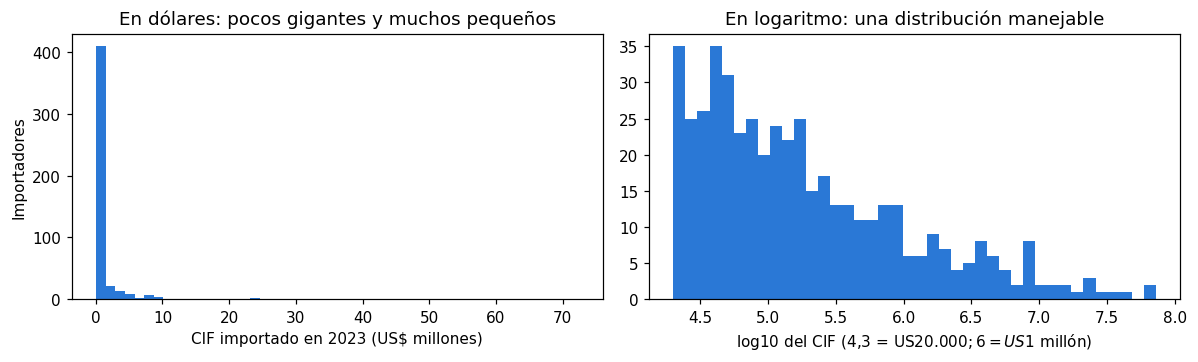

Mediana: US$120,985 | percentil 99: US$24,905,053 | máximo: US$72,374,423


In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4))
ejes[0].hist(ent["cif_t"] / 1e6, bins=50, color=AZUL)
ejes[0].set_xlabel("CIF importado en 2023 (US$ millones)"); ejes[0].set_ylabel("Importadores")
ejes[0].set_title("En dólares: pocos gigantes y muchos pequeños")
ejes[1].hist(np.log10(ent["cif_t"]), bins=40, color=AZUL)
ejes[1].set_xlabel("log10 del CIF (4,3 = US$20.000; 6 = US$1 millón)")
ejes[1].set_title("En logaritmo: una distribución manejable")
plt.tight_layout(); plt.savefig(CARPETA_SALIDA + "fig_hist_cif.png", bbox_inches="tight"); plt.show()
print(f"Mediana: US${ent.cif_t.median():,.0f} | percentil 99: US${ent.cif_t.quantile(.99):,.0f} | máximo: US${ent.cif_t.max():,.0f}")

**Para Seoru.** La mitad de los importadores trae menos de unos US\$121.000 al año, pero unos pocos traen decenas de millones. Si se ordenara a los candidatos solo por tamaño, la lista se llenaría de gigantes que tal vez no necesitan otra marca. Por eso en el modelo usamos el logaritmo del valor, y en la lista de 20 el tamaño cuenta, pero no manda.

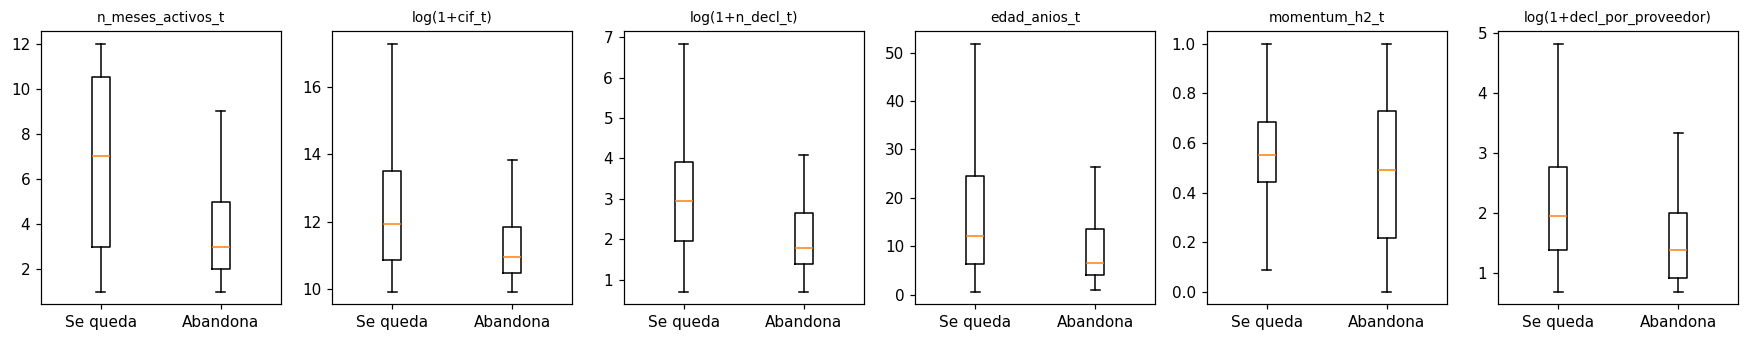

In [ ]:
cajas = ["n_meses_activos_t", "cif_t", "n_decl_t", "edad_anios_t", "momentum_h2_t", "decl_por_proveedor"]
fig, ejes = plt.subplots(1, len(cajas), figsize=(16, 3.2))
for eje, col in zip(ejes, cajas):
    valores = [ent.loc[y_ent == 0, col].dropna(), ent.loc[y_ent == 1, col].dropna()]
    if col in ("cif_t", "n_decl_t", "decl_por_proveedor"):   # estas tienen cola larga
        valores = [np.log1p(v) for v in valores]
        eje.set_title("log(1+" + col + ")", fontsize=9)
    else:
        eje.set_title(col, fontsize=9)
    eje.boxplot(valores, showfliers=False)
    eje.set_xticks([1, 2]); eje.set_xticklabels(["Se queda", "Abandona"])
plt.tight_layout(); plt.savefig(CARPETA_SALIDA + "fig_cajas.png", bbox_inches="tight"); plt.show()

**Para Seoru.** Los que abandonan importan en menos meses, traen menos valor, hacen menos declaraciones por proveedor y son empresas más jóvenes. Además traen una parte menor de su valor en el segundo semestre (mediana de 49 % frente a 55 %), como si ya vinieran frenando. Para la Directora, la constancia y el ritmo reciente de compras dicen más que el tamaño.

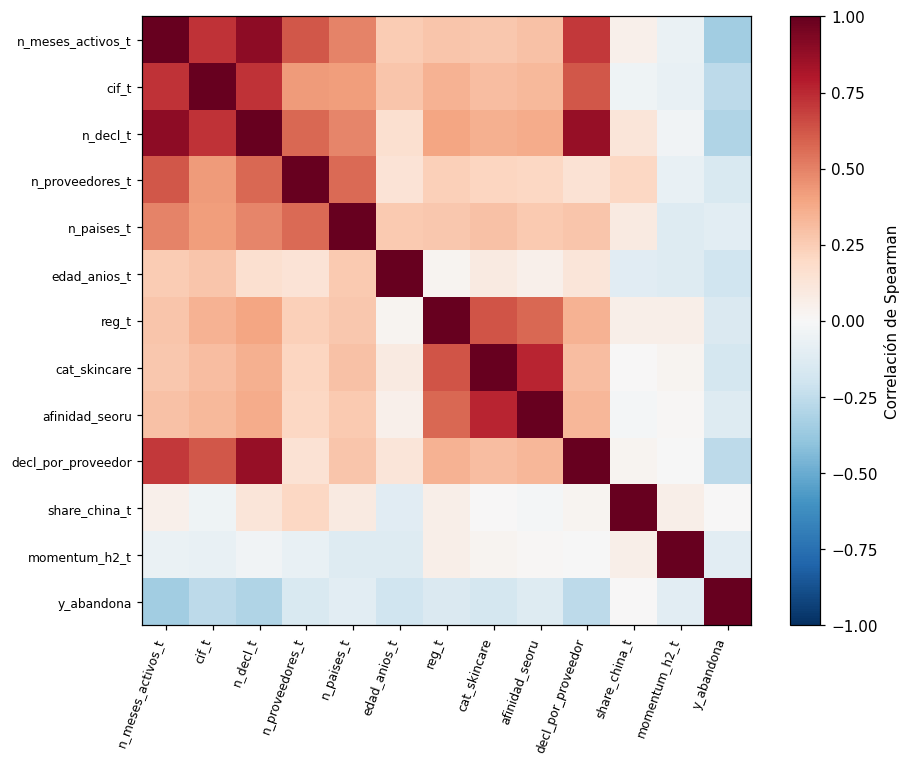

,y_abandona
n_meses_activos_t,-0.35
n_decl_t,-0.30
decl_por_proveedor,-0.26
cif_t,-0.26
edad_anios_t,-0.20
cat_skincare,-0.18
n_proveedores_t,-0.15
reg_t,-0.15
afinidad_seoru,-0.13
momentum_h2_t,-0.11


In [ ]:
cols_corr = ["n_meses_activos_t", "cif_t", "n_decl_t", "n_proveedores_t", "n_paises_t", "edad_anios_t", "reg_t",
             "cat_skincare", "afinidad_seoru", "decl_por_proveedor", "share_china_t", "momentum_h2_t", OBJETIVO]
corr = ent[cols_corr].corr(method="spearman")
plt.figure(figsize=(8.5, 7))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar(label="Correlación de Spearman")
plt.xticks(range(len(corr)), corr.columns, rotation=70, ha="right", fontsize=8); plt.yticks(range(len(corr)), corr.columns, fontsize=8)
plt.tight_layout(); plt.savefig(CARPETA_SALIDA + "fig_correlaciones.png", bbox_inches="tight"); plt.show()
corr[OBJETIVO].drop(OBJETIVO).sort_values().round(2)

**Para Seoru.** Meses activos, declaraciones, valor y proveedores se mueven juntos (correlaciones entre 0,7 y 0,9). En el fondo todos miden qué tan metido está el importador en el negocio. Por eso un modelo con muchas variables no necesariamente sabe más que la regla de los meses: buena parte de la información se repite.

## 4. Preparación dentro de un `Pipeline` (comentario 3 del monitor)

En la entrega 1 calculamos los techos del percentil 99 y las medianas con todo 2023 antes de la validación cruzada, aunque el informe decía que se calculaban dentro de cada pliegue. El monitor lo vio. Ahora todo lo que se aprende de los datos va dentro de un `Pipeline` de scikit-learn, así que en cada pliegue solo se aprende con el entrenamiento de ese pliegue:

- **Montos y conteos con cola larga:** mediana del pliegue para los vacíos, logaritmo y estandarización. Ya no recortamos en el percentil 99: el logaritmo controla la cola y así no hace falta código propio dentro del pipeline (la app solo carga piezas estándar de scikit-learn).
- **Proporciones y variables sin cola:** mediana del pliegue y estandarización.
- **Categóricas** (`forma`, `ciiu_letra`): la más frecuente para los vacíos y columnas de 0 y 1.

Los cinco modelos usan el mismo pipeline, para que la comparación sea justa.

In [ ]:
CATS_PRODUCTO = [c for c in datos.columns if c.startswith("cat_")]
COLAS_LARGAS = ["cif_t", "n_decl_t", "n_proveedores_t", "usd_por_kg_t", "reg_t", "reg_t_1", "reg_crec", "n_fabricantes_t",
                "cif_por_mes", "decl_por_mes", "decl_por_proveedor", "intensidad_sanitaria", "edad_anios_t"]
SIN_COLA = ["n_paises_t", "n_meses_activos_t", "share_china_t", "share_ue_t", "share_usa_t", "momentum_h2_t",
            "share_fab_china_t", "share_fab_extranjero_t", "n_categorias_t", "camara_bogota", "tiene_productos",
            "afinidad_seoru"] + CATS_PRODUCTO
CATEGORICAS = ["forma", "ciiu_letra"]
ENTRADA = COLAS_LARGAS + SIN_COLA + CATEGORICAS

def preparacion(con_texto=False, sin_afinidad=False):
    sin_cola = [c for c in SIN_COLA if not (sin_afinidad and c == "afinidad_seoru")]
    pasos = [
        ("colas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                            ("escalar", StandardScaler())]), COLAS_LARGAS),
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), sin_cola),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("codificar", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAS),
    ]
    if con_texto:  # solo para la prueba de la sección 8.1: los temas se aprenden dentro de cada pliegue
        pasos.append(("texto", Pipeline([("tfidf", TfidfVectorizer(min_df=5, max_df=0.4, ngram_range=(1, 2), sublinear_tf=True)),
                                         ("temas", NMF(8, init="nndsvda", random_state=SEMILLA, max_iter=800))]), "texto_limpio"))
    return ColumnTransformer(pasos)

print(len(ENTRADA), "columnas de entrada:", ENTRADA)

37 columnas de entrada: ['cif_t', 'n_decl_t', 'n_proveedores_t', 'usd_por_kg_t', 'reg_t', 'reg_t_1', 'reg_crec', 'n_fabricantes_t', 'cif_por_mes', 'decl_por_mes', 'decl_por_proveedor', 'intensidad_sanitaria', 'edad_anios_t', 'n_paises_t', 'n_meses_activos_t', 'share_china_t', 'share_ue_t', 'share_usa_t', 'momentum_h2_t', 'share_fab_china_t', 'share_fab_extranjero_t', 'n_categorias_t', 'camara_bogota', 'tiene_productos', 'afinidad_seoru', 'cat_skincare', 'cat_maquillaje', 'cat_capilar', 'cat_fragancia', 'cat_corporal', 'cat_unas', 'cat_solar', 'cat_oral', 'cat_desodorante', 'cat_hombre', 'forma', 'ciiu_letra']


## 5. Funciones de costo, umbrales y regla simple

- Con una probabilidad `p` y dos umbrales `u1 ≤ u2`: firmar si `p < u1`, garantías si `u1 ≤ p < u2` y no firmar si `p ≥ u2`. Si `u1 = u2`, no hay tramo de garantías.
- La regla simple usa los meses con importaciones: no firmar si son menos de `a`, garantías de `a` a `b−1` y firmar desde `b`.
- Los umbrales y los cortes de la regla se eligen buscando el menor costo, siempre con datos de entrenamiento.

In [ ]:
UMBRALES = np.round(np.arange(0.02, 0.71, 0.01), 2)

def costo_por_fila(decision, y, costos=COSTOS):
    decision, y = np.asarray(decision), np.asarray(y)
    costo = np.zeros(len(y))
    for (d, real), valor in costos.items():
        costo[(decision == d) & (y == real)] = valor
    return costo

def costo_100(decision, y, costos=COSTOS):
    # costo promedio por cada 100 importadores, que es la unidad que pide el brief
    return costo_por_fila(decision, y, costos).mean() * 100

def decidir(prob, u1, u2):
    prob = np.asarray(prob)
    return np.where(prob < u1, "firmar", np.where(prob < u2, "garantias", "no_firmar"))

def mejores_umbrales(prob, y, costos=COSTOS):
    # probamos todas las parejas u1 <= u2 y nos quedamos con la más barata
    mejor = (np.inf, None, None)
    for u1 in UMBRALES:
        for u2 in UMBRALES[UMBRALES >= u1]:
            c = costo_100(decidir(prob, u1, u2), y, costos)
            if c < mejor[0] - 1e-9:
                mejor = (c, u1, u2)
    return mejor

def regla(meses, a, b):
    meses = np.asarray(meses)
    return np.where(meses < a, "no_firmar", np.where(meses < b, "garantias", "firmar"))

def mejor_regla(meses, y, costos=COSTOS):
    mejor = (np.inf, None, None)
    for a in range(1, 14):
        for b in range(a, 14):  # b = 13 quiere decir que nunca se firma sin garantías
            c = costo_100(regla(meses, a, b), y, costos)
            if c < mejor[0] - 1e-9:
                mejor = (c, a, b)
    return mejor

def prob_fuera_de_pliegue(estimador, X, y, divisor, grupos=None):
    # cada fila recibe la probabilidad de un modelo que no la vio al entrenar
    prob = np.zeros(len(y))
    for i_ent, i_val in divisor.split(X, y, grupos):
        modelo = clone(estimador).fit(X.iloc[i_ent], y[i_ent])
        prob[i_val] = modelo.predict_proba(X.iloc[i_val])[:, 1]
    return prob

def texto_regla(a, b):
    if a == b:
        return f"No firmar si importó menos de {a} meses; firmar desde {a}"
    if b == a + 1:
        return f"No firmar si importó menos de {a} meses; garantías si importó {a}; firmar desde {b}"
    return f"No firmar si importó menos de {a} meses; garantías de {a} a {b - 1}; firmar desde {b}"

## 6. Modelado y evaluación: cinco competidores con la misma validación y el mismo costo
### 6.1 Los candidatos

De cada modelo probamos varias versiones (hiperparámetros). Los dos ensambles se comparan con el árbol porque los tres están hechos de árboles: el bosque promedia muchos árboles independientes y XGBoost los arma uno detrás de otro, cada uno corrigiendo los errores del anterior.

In [ ]:
def candidatos(con_texto=False, sin_afinidad=False):
    c = {}
    for C in [0.01, 0.03, 0.1, 0.3, 1.0]:
        c[f"Logística C={C}"] = ("Regresión logística", LogisticRegression(C=C, max_iter=5000))
    for prof in [2, 3, 4, 5]:
        for hoja in [10, 20, 40]:
            c[f"Árbol prof={prof} hoja={hoja}"] = ("Árbol de decisión", DecisionTreeClassifier(
                max_depth=prof, min_samples_leaf=hoja, random_state=SEMILLA))
    for prof in [3, 5, None]:
        for hoja in [5, 10, 20]:
            c[f"Bosque prof={prof} hoja={hoja}"] = ("Bosque aleatorio", RandomForestClassifier(
                n_estimators=300, max_depth=prof, min_samples_leaf=hoja, max_features="sqrt", random_state=SEMILLA, n_jobs=-1))
    # XGBoost: pocas combinaciones, árboles poco profundos y tasa baja (con 477 filas se sobreajusta fácil)
    for n, prof, tasa in [(100, 2, 0.05), (300, 2, 0.03), (400, 2, 0.01), (200, 3, 0.05), (300, 3, 0.03), (100, 4, 0.05)]:
        c[f"XGBoost n={n} prof={prof} tasa={tasa}"] = ("XGBoost", XGBClassifier(
            n_estimators=n, max_depth=prof, learning_rate=tasa, subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
            random_state=SEMILLA, n_jobs=2, eval_metric="logloss"))
    # cada versión queda como pipeline completo: preparación + modelo
    return {nombre: (familia, Pipeline([("preparacion", preparacion(con_texto, sin_afinidad)), ("modelo", m)]))
            for nombre, (familia, m) in c.items()}

CANDIDATOS = candidatos()
FAMILIAS = ["Regresión logística", "Árbol de decisión", "Bosque aleatorio", "XGBoost"]
pd.Series([f for f, _ in CANDIDATOS.values()]).value_counts().rename("versiones probadas")

,versiones probadas
Árbol de decisión,12
Bosque aleatorio,9
XGBoost,6
Regresión logística,5


### 6.2 Validación cruzada anidada dentro de 2023 (comentario 4 del monitor)

En la entrega 1 elegimos los umbrales y medimos el costo con las mismas probabilidades, y por eso esa cifra salía optimista. Ahora va en dos niveles:

1. **Pliegues externos (5):** apartan un pedazo de 2023 que nadie toca hasta el final.
2. **Pliegues internos (5),** con el resto: ahí se escogen la versión de cada modelo y sus dos umbrales (o los cortes de la regla) por costo.
3. Lo escogido se mide en el pliegue externo. El promedio de los 5 externos es el costo "limpio" con el que comparamos.

Esta celda se demora varios minutos.

In [ ]:
def validacion_anidada(candidatos_dict, X, y, incluir_regla=True, semilla=SEMILLA):
    externos = StratifiedKFold(K, shuffle=True, random_state=semilla)
    filas = []
    for k, (i_a, i_b) in enumerate(externos.split(X, y), start=1):
        Xa, ya = X.iloc[i_a].reset_index(drop=True), y[i_a]
        Xb, yb = X.iloc[i_b].reset_index(drop=True), y[i_b]
        internos = StratifiedKFold(K, shuffle=True, random_state=semilla + k)
        # nivel interno: la mejor versión de cada familia, con sus umbrales
        mejor = {}
        for nombre, (familia, est) in candidatos_dict.items():
            p = prob_fuera_de_pliegue(est, Xa, ya, internos)
            c, u1, u2 = mejores_umbrales(p, ya)
            if familia not in mejor or c < mejor[familia][0]:
                mejor[familia] = (c, nombre, u1, u2)
        # nivel externo: se mide lo elegido en datos que no participaron en la elección
        for familia, (c, nombre, u1, u2) in mejor.items():
            pb = clone(candidatos_dict[nombre][1]).fit(Xa, ya).predict_proba(Xb)[:, 1]
            filas.append({"Pliegue": k, "Modelo": familia, "Versión elegida": nombre, "u1": u1, "u2": u2,
                          "Costo por 100": costo_100(decidir(pb, u1, u2), yb), "AUC": roc_auc_score(yb, pb)})
        if incluir_regla:
            _, a, b = mejor_regla(Xa["n_meses_activos_t"].values, ya)
            filas.append({"Pliegue": k, "Modelo": "Regla simple", "Versión elegida": texto_regla(a, b), "u1": a, "u2": b,
                          "Costo por 100": costo_100(regla(Xb["n_meses_activos_t"].values, a, b), yb),
                          "AUC": roc_auc_score(yb, -Xb["n_meses_activos_t"].values)})
    return pd.DataFrame(filas)

inicio = time.time()
anidada = validacion_anidada(CANDIDATOS, ent, y_ent)
print(f"Tiempo: {time.time() - inicio:.0f} s")
anidada.to_csv(CARPETA_SALIDA + "validacion_anidada_detalle.csv", index=False)
resumen_anidada = anidada.groupby("Modelo").agg(costo_medio=("Costo por 100", "mean"), costo_de=("Costo por 100", "std"),
                                                auc_medio=("AUC", "mean")).sort_values("costo_medio")
resumen_anidada.to_csv(CARPETA_SALIDA + "validacion_anidada_resumen.csv")
(resumen_anidada.assign(costo_medio=lambda t: t.costo_medio / 1e6, costo_de=lambda t: t.costo_de / 1e6)
 .rename(columns={"costo_medio": "Costo medio (US$ M por 100)", "costo_de": "DE entre pliegues", "auc_medio": "AUC medio"}).round(3))

Tiempo: 332 s


,Costo medio (US$ M por 100),DE entre pliegues,AUC medio
Modelo,,,
Regla simple,2.519,0.477,0.744
Árbol de decisión,2.599,0.540,0.699
Bosque aleatorio,2.768,0.237,0.740
XGBoost,2.821,0.421,0.738
Regresión logística,2.906,0.521,0.720


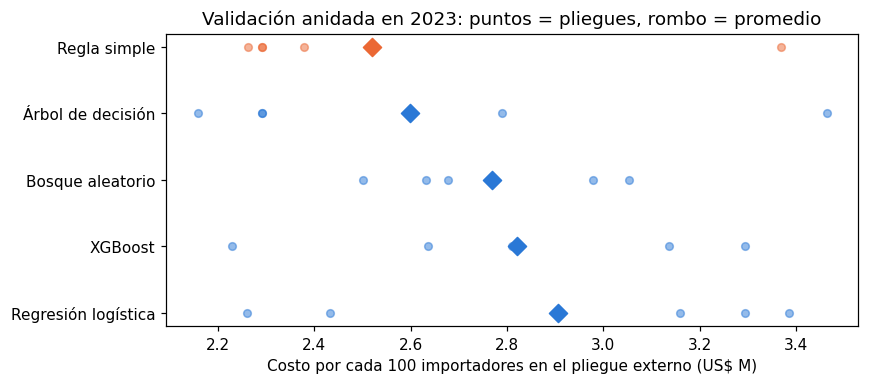

In [ ]:
orden = resumen_anidada.index.tolist()
plt.figure(figsize=(8, 3.6))
for i, m in enumerate(orden):
    v = anidada.loc[anidada.Modelo == m, "Costo por 100"] / 1e6
    color = NARANJA if m == "Regla simple" else AZUL
    plt.scatter(v, [i] * len(v), color=color, alpha=0.5, s=25)
    plt.scatter(v.mean(), i, color=color, marker="D", s=70, zorder=3)
plt.yticks(range(len(orden)), orden); plt.gca().invert_yaxis()
plt.xlabel("Costo por cada 100 importadores en el pliegue externo (US$ M)")
plt.title("Validación anidada en 2023: puntos = pliegues, rombo = promedio")
plt.tight_layout(); plt.savefig(CARPETA_SALIDA + "fig_anidada.png", bbox_inches="tight"); plt.show()

**Qué vemos.** Con la validación limpia ningún modelo le gana a la regla de los meses: la regla tiene el costo promedio más bajo. Los modelos quedan cerca entre sí, y la diferencia entre ellos es menor que lo que varía cada uno de un pliegue a otro. Tampoco ordenan mejor que los meses solos: el AUC de la regla, usando los meses como puntaje, es igual al del mejor ensamble. La explicación es que meses, declaraciones, valor y proveedores dicen casi lo mismo, y la regla ya recoge esa señal.

### 6.3 Versión final de cada modelo y prueba en 2024 (se usa una sola vez)

Para cada familia escogemos la versión y los umbrales con validación cruzada en todo 2023, entrenamos con todo 2023 y medimos una sola vez en 2024. La regla también se ajusta solo con 2023.

In [ ]:
divisor = StratifiedKFold(K, shuffle=True, random_state=SEMILLA)
elegidos = {}
for nombre, (familia, est) in CANDIDATOS.items():
    p = prob_fuera_de_pliegue(est, ent, y_ent, divisor)
    c, u1, u2 = mejores_umbrales(p, y_ent)
    if familia not in elegidos or c < elegidos[familia]["costo_vc"]:
        elegidos[familia] = {"versión": nombre, "costo_vc": c, "u1": u1, "u2": u2, "auc_vc": roc_auc_score(y_ent, p), "prob_vc": p}
_, A_REGLA, B_REGLA = mejor_regla(ent["n_meses_activos_t"].values, y_ent)
REGLA_TEXTO = texto_regla(A_REGLA, B_REGLA)
print("Regla ajustada con 2023:", REGLA_TEXTO)
pd.DataFrame({f: {k: v for k, v in e.items() if k != "prob_vc"} for f, e in elegidos.items()}).T

Regla ajustada con 2023: No firmar si importó menos de 7 meses; firmar desde 7


,versión,costo_vc,u1,u2,auc_vc
Regresión logística,Logística C=0.01,2649895.178197,0.14,0.23,0.722405
Árbol de decisión,Árbol prof=2 hoja=40,2505241.090147,0.18,0.18,0.700392
Bosque aleatorio,Bosque prof=None hoja=20,2505241.090147,0.16,0.16,0.729621
XGBoost,XGBoost n=400 prof=2 tasa=0.01,2603773.584906,0.13,0.14,0.732392


In [ ]:
n_pru = len(y_pru)
rng = np.random.default_rng(SEMILLA)
muestras = rng.integers(0, n_pru, size=(N_BOOT, n_pru))   # las mismas 1.000 muestras para todos

decisiones, puntajes, modelos_2023 = {}, {}, {}
decisiones["Firmar con todos"] = np.repeat("firmar", n_pru)
decisiones["Garantías a todos"] = np.repeat("garantias", n_pru)
decisiones["No firmar con nadie"] = np.repeat("no_firmar", n_pru)
decisiones["Regla simple"] = regla(pru["n_meses_activos_t"], A_REGLA, B_REGLA)
puntajes["Regla simple"] = -pru["n_meses_activos_t"].values
for familia in FAMILIAS:
    e = elegidos[familia]
    modelos_2023[familia] = clone(CANDIDATOS[e["versión"]][1]).fit(ent, y_ent)
    p = modelos_2023[familia].predict_proba(pru)[:, 1]
    puntajes[familia] = p
    decisiones[familia] = decidir(p, e["u1"], e["u2"])

costos_fila = {k: costo_por_fila(d, y_pru) for k, d in decisiones.items()}
boot = {k: c[muestras].mean(axis=1) * 100 for k, c in costos_fila.items()}
pocos = pru["n_meses_activos_t"].values < A_REGLA   # los que la regla descarta
filas = []
for k, d in decisiones.items():
    marcado = d != "firmar"
    vp = (marcado & (y_pru == 1)).sum()
    dif = boot[k] - boot["Regla simple"]
    filas.append({"Decisión": k,
                  "Costo por 100": costos_fila[k].mean() * 100,
                  "IC inf": np.percentile(boot[k], 2.5), "IC sup": np.percentile(boot[k], 97.5),
                  "Dif. vs regla": (costos_fila[k].mean() - costos_fila["Regla simple"].mean()) * 100,
                  "Dif. IC inf": np.percentile(dif, 2.5), "Dif. IC sup": np.percentile(dif, 97.5),
                  "Sensibilidad": vp / (y_pru == 1).sum(),
                  "Precisión": vp / marcado.sum() if marcado.sum() else np.nan,
                  "AUC": roc_auc_score(y_pru, puntajes[k]) if k in puntajes else np.nan,
                  "Pocos meses → garantías": int((pocos & (d == "garantias")).sum()),
                  "Pocos meses → firmar": int((pocos & (d == "firmar")).sum())})
tabla_prueba = pd.DataFrame(filas).set_index("Decisión")
tabla_prueba.to_csv(CARPETA_SALIDA + "tabla_prueba_2024.csv")
vista = tabla_prueba.copy()
for c in ["Costo por 100", "IC inf", "IC sup", "Dif. vs regla", "Dif. IC inf", "Dif. IC sup"]:
    vista[c] = vista[c] / 1e6
vista.round(3)

,Costo por 100,IC inf,IC sup,Dif. vs regla,Dif. IC inf,Dif. IC sup,Sensibilidad,Precisión,AUC,Pocos meses → garantías,Pocos meses → firmar
Decisión,,,,,,,,,,,
Firmar con todos,5.010,4.236,5.888,2.138,1.312,3.110,0.000,NaN,NaN,0,267
Garantías a todos,4.004,3.694,4.355,1.132,0.647,1.690,1.000,0.200,NaN,267,0
No firmar con nadie,3.998,3.822,4.153,1.126,0.589,1.591,1.000,0.200,NaN,0,0
Regla simple,2.872,2.438,3.327,0.000,0.000,0.000,0.814,0.296,0.728,0,0
Regresión logística,2.841,2.465,3.217,-0.031,-0.298,0.254,0.897,0.269,0.740,62,4
Árbol de decisión,2.872,2.438,3.327,0.000,0.000,0.000,0.814,0.296,0.707,0,0
Bosque aleatorio,2.872,2.469,3.296,0.000,-0.238,0.217,0.835,0.290,0.739,0,9
XGBoost,2.829,2.419,3.252,-0.043,-0.287,0.176,0.835,0.293,0.732,4,9


**Qué vemos.** En 2024 la regla cuesta lo mismo que los modelos. Todas las diferencias frente a la regla son de unas pocas decenas de miles de dólares por cada 100 importadores, y todos los intervalos incluyen el cero. Con unos 100 abandonos en la prueba no se alcanzan a ver diferencias menores a unos US\$0,25 M por cada 100. Lo que sí está claro es que cualquiera de ellos ahorra más de US\$1 M por cada 100 frente a decidir sin criterio.

**¿Cuántos importadores de pocos meses pasan a garantías?** (comentario 2 del monitor). Las dos últimas columnas cuentan a los importadores que la regla descarta (menos meses que el corte) y que el modelo manda a garantías o a firmar. La logística es la que más "rescata" con garantías, pero esos rescates no bajan el costo de forma clara.

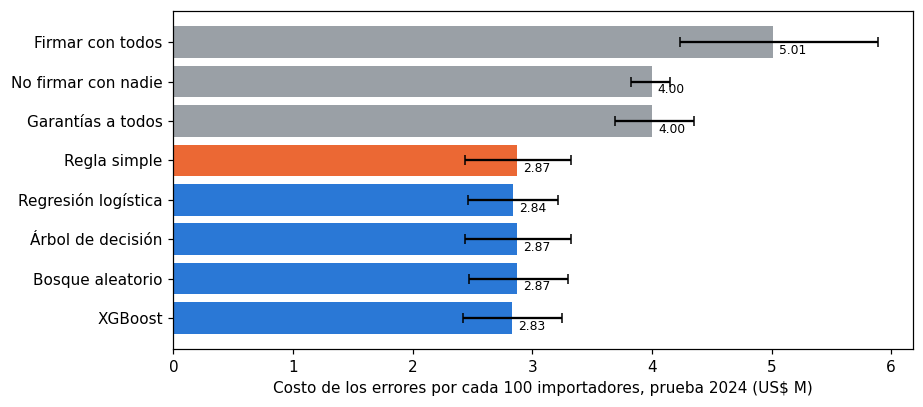

In [ ]:
# costo por 100 con su intervalo (es la figura 1 del informe)
orden_fig = ["Firmar con todos", "No firmar con nadie", "Garantías a todos", "Regla simple"] + FAMILIAS
t = tabla_prueba.loc[orden_fig]
colores = [GRIS, GRIS, GRIS, NARANJA] + [AZUL] * 4
plt.figure(figsize=(8.5, 3.8))
y_pos = np.arange(len(t))
plt.barh(y_pos, t["Costo por 100"] / 1e6, color=colores)
plt.errorbar(t["Costo por 100"] / 1e6, y_pos, xerr=[(t["Costo por 100"] - t["IC inf"]) / 1e6, (t["IC sup"] - t["Costo por 100"]) / 1e6],
             fmt="none", color="black", capsize=3)
for i, v in enumerate(t["Costo por 100"] / 1e6):
    plt.text(v + 0.05, i + 0.3, f"{v:.2f}", fontsize=8)
plt.yticks(y_pos, t.index); plt.gca().invert_yaxis()
plt.xlabel("Costo de los errores por cada 100 importadores, prueba 2024 (US$ M)")
plt.tight_layout(); plt.savefig(CARPETA_SALIDA + "fig_costos_2024.png", bbox_inches="tight"); plt.show()

### 6.4 ¿Qué modelo lleva el radar?

El criterio lo fijamos antes de mirar 2024: entre los cuatro modelos gana el de menor costo en la validación anidada. Si la diferencia con los demás es menor que la desviación estándar entre pliegues, desempata el que mejor ordena (AUC anidado), porque la lista de 20 candidatos depende de ordenar bien.

In [ ]:
solo_modelos = resumen_anidada.drop(index="Regla simple")
primero = solo_modelos.index[0]
empatados = solo_modelos[solo_modelos.costo_medio - solo_modelos.costo_medio.iloc[0] < solo_modelos.costo_de.iloc[0]]
RADAR = empatados["auc_medio"].idxmax()
print("Menor costo anidado:", primero, "| empatados con él:", empatados.index.tolist())
print("Modelo del radar:", RADAR, "→", elegidos[RADAR]["versión"], "| umbrales", elegidos[RADAR]["u1"], elegidos[RADAR]["u2"])

Menor costo anidado: Árbol de decisión | empatados con él: ['Árbol de decisión', 'Bosque aleatorio', 'XGBoost', 'Regresión logística']
Modelo del radar: Bosque aleatorio → Bosque prof=None hoja=20 | umbrales 0.16 0.16


### 6.5 Matriz de confusión en dólares y curva de costo del modelo del radar (2024)

In [ ]:
def matriz_dolares(decision, y, costos=COSTOS):
    cuenta = pd.crosstab(pd.Series(decision, name="Decisión"), pd.Series(np.where(y == 1, "Abandona", "Se queda"), name="Real"))
    cuenta = cuenta.reindex(index=["firmar", "garantias", "no_firmar"], columns=["Se queda", "Abandona"], fill_value=0)
    dinero = cuenta.astype(float).copy()
    for d in dinero.index:
        dinero.loc[d, "Se queda"] *= costos[(d, 0)]
        dinero.loc[d, "Abandona"] *= costos[(d, 1)]
    return cuenta, dinero

for nombre in [RADAR, "Regla simple"]:
    cuenta, dinero = matriz_dolares(decisiones[nombre], y_pru)
    print(f"\n{nombre}: total US${dinero.values.sum() / 1e6:.2f} M en {n_pru} importadores = US${dinero.values.sum() / n_pru * 100 / 1e6:.2f} M por 100")
    display(cuenta.astype(str) + " · US$" + (dinero / 1e6).round(2).astype(str) + " M")


Bosque aleatorio: total US$13.90 M en 484 importadores = US$2.87 M por 100


Real,Se queda,Abandona
Decisión,,
firmar,189 · US$0.0 M,16 · US$4.0 M
garantias,0 · US$0.0 M,0 · US$0.0 M
no_firmar,198 · US$9.9 M,81 · US$0.0 M



Regla simple: total US$13.90 M en 484 importadores = US$2.87 M por 100


Real,Se queda,Abandona
Decisión,,
firmar,199 · US$0.0 M,18 · US$4.5 M
garantias,0 · US$0.0 M,0 · US$0.0 M
no_firmar,188 · US$9.4 M,79 · US$0.0 M


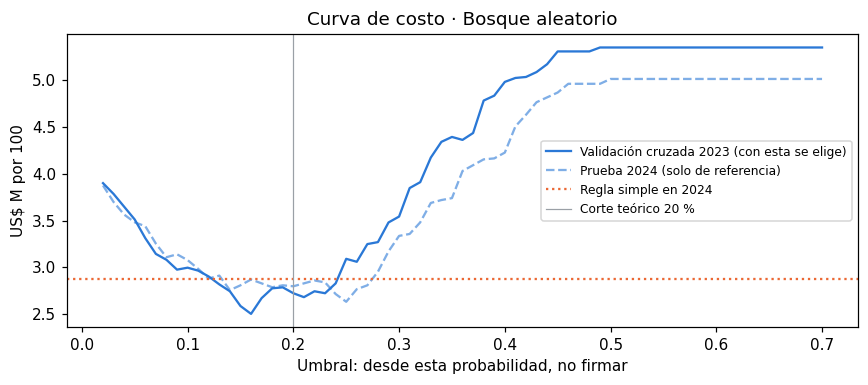

In [ ]:
p_radar_pru = puntajes[RADAR]
p_radar_vc = elegidos[RADAR]["prob_vc"]
# un solo umbral (sin garantías), para ver cómo cambia el costo
curva = pd.DataFrame({"umbral": UMBRALES,
                      "VC 2023": [costo_100(decidir(p_radar_vc, u, u), y_ent) for u in UMBRALES],
                      "Prueba 2024": [costo_100(decidir(p_radar_pru, u, u), y_pru) for u in UMBRALES]})
plt.figure(figsize=(8, 3.6))
plt.plot(curva.umbral, curva["VC 2023"] / 1e6, color=AZUL, label="Validación cruzada 2023 (con esta se elige)")
plt.plot(curva.umbral, curva["Prueba 2024"] / 1e6, color=AZUL, ls="--", alpha=0.6, label="Prueba 2024 (solo de referencia)")
plt.axhline(costos_fila["Regla simple"].mean() * 100 / 1e6, color=NARANJA, ls=":", label="Regla simple en 2024")
plt.axvline(0.20, color=GRIS, lw=0.8, label="Corte teórico 20 %")
plt.xlabel("Umbral: desde esta probabilidad, no firmar"); plt.ylabel("US$ M por 100")
plt.title(f"Curva de costo · {RADAR}"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(CARPETA_SALIDA + "fig_curva_costo.png", bbox_inches="tight"); plt.show()

### 6.6 Sensibilidad a los costos (comentario 5 del monitor)

La conclusión depende de dos supuestos que nadie ha medido: cuánto pierde Seoru al descartar a un buen socio (US\$50.000) y cuánto cuestan las garantías (US\$20.000). Los cambiamos uno a la vez. En cada escenario volvemos a ajustar con 2023 el corte de la regla y los umbrales del modelo (la versión del modelo no cambia) y medimos en 2024.

In [ ]:
ESCENARIOS = {"Base (50.000 y 20.000)": (50_000, 20_000),
              "Perder un buen socio cuesta 30.000": (30_000, 20_000),
              "Perder un buen socio cuesta 80.000": (80_000, 20_000),
              "Garantías cuestan 10.000": (50_000, 10_000),
              "Garantías cuestan 40.000": (50_000, 40_000)}
filas = []
for nombre, (perder, gar) in ESCENARIOS.items():
    cst = tabla_costos(perder, gar)
    _, a, b = mejor_regla(ent["n_meses_activos_t"].values, y_ent, cst)   # se reajusta con 2023
    _, u1, u2 = mejores_umbrales(p_radar_vc, y_ent, cst)
    d_reg = regla(pru["n_meses_activos_t"], a, b)
    d_mod = decidir(p_radar_pru, u1, u2)
    c_reg, c_mod = costo_por_fila(d_reg, y_pru, cst), costo_por_fila(d_mod, y_pru, cst)
    dif = (c_mod[muestras].mean(1) - c_reg[muestras].mean(1)) * 100
    filas.append({"Escenario": nombre, "Regla": texto_regla(a, b), "Umbrales del modelo": f"{u1:.2f} / {u2:.2f}",
                  "Costo regla": c_reg.mean() * 100 / 1e6, "Costo modelo": c_mod.mean() * 100 / 1e6,
                  "Dif. modelo − regla": (c_mod.mean() - c_reg.mean()) * 100 / 1e6,
                  "IC dif.": f"{np.percentile(dif, 2.5) / 1e6:+.2f} a {np.percentile(dif, 97.5) / 1e6:+.2f}",
                  "Modelo: % garantías": (d_mod == "garantias").mean(), "Modelo: % no firmar": (d_mod == "no_firmar").mean()})
sensibilidad = pd.DataFrame(filas).set_index("Escenario")
sensibilidad.to_csv(CARPETA_SALIDA + "tabla_sensibilidad.csv")
sensibilidad.round(2)

,Regla,Umbrales del modelo,Costo regla,Costo modelo,Dif. modelo − regla,IC dif.,Modelo: % garantías,Modelo: % no firmar
Escenario,,,,,,,,
Base (50.000 y 20.000),No firmar si importó menos de 7 meses; firmar ...,0.16 / 0.16,2.87,2.87,0.00,-0.24 a +0.22,0.00,0.58
Perder un buen socio cuesta 30.000,No firmar si importó menos de 7 meses; firmar ...,0.16 / 0.16,2.10,2.05,-0.04,-0.26 a +0.16,0.00,0.58
Perder un buen socio cuesta 80.000,No firmar si importó menos de 3 meses; garantí...,0.16 / 0.24,3.39,3.58,0.19,-0.20 a +0.59,0.14,0.43
Garantías cuestan 10.000,No firmar si importó menos de 5 meses; garantí...,0.07 / 0.23,2.57,2.51,-0.05,-0.24 a +0.14,0.36,0.46
Garantías cuestan 40.000,No firmar si importó menos de 7 meses; firmar ...,0.16 / 0.16,2.87,2.87,0.00,-0.24 a +0.22,0.00,0.58


**Qué vemos.** Si perder un buen socio cuesta 30.000, o si las garantías cuestan 40.000, nada cambia: la regla sigue en 7 meses y el modelo en el mismo umbral. Lo que mueve la decisión es lo contrario. Si perder un buen socio cuesta 80.000, la regla se vuelve más flexible (garantías para los que importaron de 3 a 6 meses) y el modelo empieza a usar garantías. Si las garantías costaran 10.000, la regla las pide de 5 a 9 meses y el modelo se las pide a más de un tercio de los importadores. En ningún escenario el modelo le gana a la regla con un intervalo que deje por fuera el cero, así que la recomendación (decidir con la constancia y usar el modelo para ordenar) se sostiene. Lo que sí cambia es a quién pedirle garantías, y por eso el Gerente Financiero debería validar esas dos cifras antes de firmar.

## 7. Qué explica el modelo y dónde se equivoca
### 7.1 Importancia por permutación (prueba 2024)

Desordenamos una columna a la vez en los datos de 2024 y medimos cuánto baja el AUC. Si baja mucho, el modelo depende de esa columna. Ojo: esto no dice que cambiar la variable cambie el abandono, solo en qué se apoya el modelo para predecir.

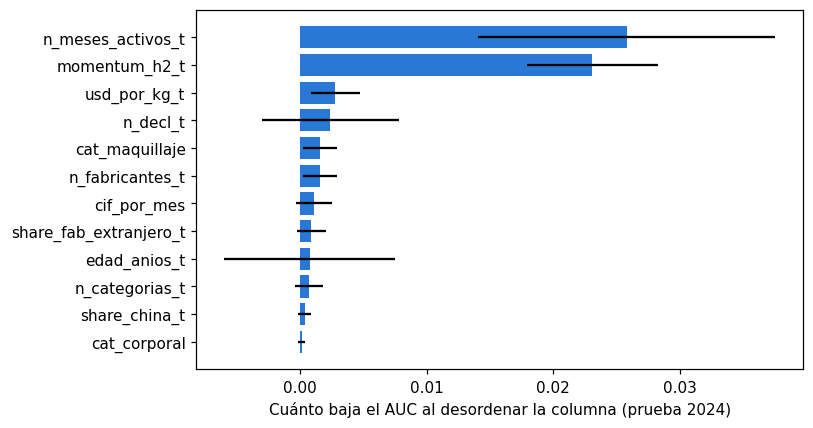

,Baja del AUC,DE
n_meses_activos_t,0.0258,0.0117
momentum_h2_t,0.0231,0.0052
usd_por_kg_t,0.0028,0.0019
n_decl_t,0.0024,0.0054
cat_maquillaje,0.0016,0.0014
n_fabricantes_t,0.0016,0.0014
cif_por_mes,0.0011,0.0014
share_fab_extranjero_t,0.0009,0.0011
edad_anios_t,0.0008,0.0068
n_categorias_t,0.0007,0.0011


In [ ]:
modelo_radar_2023 = modelos_2023[RADAR]
perm = permutation_importance(modelo_radar_2023, pru[ENTRADA], y_pru, scoring="roc_auc", n_repeats=30, random_state=SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"Baja del AUC": perm.importances_mean, "DE": perm.importances_std}, index=ENTRADA).sort_values("Baja del AUC", ascending=False)
importancia.to_csv(CARPETA_SALIDA + "importancia_permutacion.csv")
top = importancia.head(12)[::-1]
plt.figure(figsize=(7.5, 4))
plt.barh(top.index, top["Baja del AUC"], xerr=top["DE"], color=AZUL)
plt.xlabel("Cuánto baja el AUC al desordenar la columna (prueba 2024)")
plt.tight_layout(); plt.savefig(CARPETA_SALIDA + "fig_permutacion.png", bbox_inches="tight"); plt.show()
importancia.head(10).round(4)

**Qué vemos.** El modelo se apoya sobre todo en dos columnas: los meses con importaciones (igual que la regla) y la parte del valor que se importó en el segundo semestre. Las demás bajan muy poco el AUC cuando se desordenan una por una, porque se repiten entre sí: si se desordena el valor, el modelo todavía tiene las declaraciones. Que una variable salga arriba no quiere decir que cambiarla cambie el abandono. Pedirle a un importador que compre más en el segundo semestre no lo vuelve mejor socio; es una señal de cómo le venía yendo, no una palanca.

### 7.2 SHAP: cómo empuja cada variable la predicción de cada importador

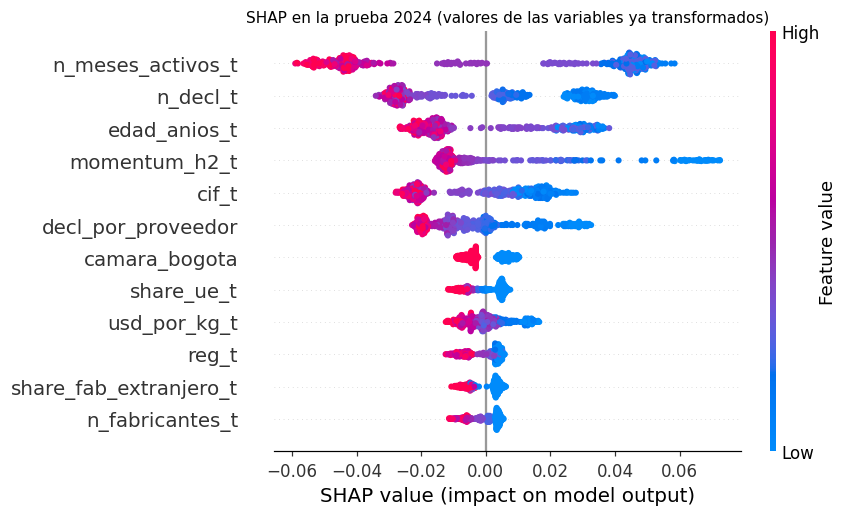

,0
n_meses_activos_t,0.0419
n_decl_t,0.0232
edad_anios_t,0.0200
momentum_h2_t,0.0165
cif_t,0.0156
decl_por_proveedor,0.0124
camara_bogota,0.0057
share_ue_t,0.0053
usd_por_kg_t,0.0049
reg_t,0.0045


In [ ]:
prep_r = modelo_radar_2023.named_steps["preparacion"]
mod_r = modelo_radar_2023.named_steps["modelo"]
X_pru_t = prep_r.transform(pru[ENTRADA])
X_pru_t = X_pru_t.toarray() if hasattr(X_pru_t, "toarray") else X_pru_t
nombres_t = [n.split("__", 1)[1] for n in prep_r.get_feature_names_out()]
X_pru_t = pd.DataFrame(X_pru_t, columns=nombres_t)
if isinstance(mod_r, LogisticRegression):
    explicador = shap.LinearExplainer(mod_r, X_pru_t)
else:
    explicador = shap.TreeExplainer(mod_r)
valores_shap = explicador.shap_values(X_pru_t)
# según la versión de shap sale una lista o un arreglo 3D; nos quedamos con la clase 1 (abandona)
if isinstance(valores_shap, list):
    valores_shap = valores_shap[1]
if np.ndim(valores_shap) == 3:
    valores_shap = valores_shap[:, :, 1]
shap.summary_plot(valores_shap, X_pru_t, max_display=12, show=False, plot_size=(8, 4.8))
plt.title("SHAP en la prueba 2024 (valores de las variables ya transformados)", fontsize=10)
plt.tight_layout(); plt.savefig(CARPETA_SALIDA + "fig_shap.png", bbox_inches="tight"); plt.show()
shap_medio = pd.Series(np.abs(valores_shap).mean(0), index=nombres_t).sort_values(ascending=False)
shap_medio.head(10).round(4)

**Qué vemos.** Cada punto es un importador de 2024. El rojo es un valor alto de la variable y el azul uno bajo; hacia la derecha sube la probabilidad de abandono. Pocos meses activos (azul) empujan fuerte a la derecha, y lo mismo pasa con pocas declaraciones, poca antigüedad, poco valor en el segundo semestre y poco valor total, que son las mismas señales de la exploración. SHAP reparte el peso entre variables parecidas (meses, declaraciones, valor), y por eso su orden no es idéntico al de la permutación. Igual que antes, SHAP explica al modelo y no al mundo: no dice qué pasaría si un importador importara más meses.

### 7.3 Análisis de errores: en qué importadores se equivoca más

Comparamos los errores del modelo del radar con los de la regla, por tipo de importador.

In [ ]:
def tramo_meses(m):
    return pd.cut(m, [0, 3, 6, 9, 12], labels=["1–3 meses", "4–6 meses", "7–9 meses", "10–12 meses"])

cortes_tam = ent["cif_t"].quantile([0.2, 0.4, 0.6, 0.8]).values   # quintiles de tamaño fijados con 2023
err = pru[["n_meses_activos_t", "cif_t", "edad_anios_t", "tiene_productos", "afinidad_seoru"]].copy()
err["y"] = y_pru
err["Meses"] = tramo_meses(err["n_meses_activos_t"])
err["Tamaño"] = pd.cut(err["cif_t"], [-np.inf, *cortes_tam, np.inf], labels=["Q1 menor", "Q2", "Q3", "Q4", "Q5 mayor"])
err["Antigüedad"] = pd.cut(err["edad_anios_t"], [-np.inf, 5, 10, np.inf], labels=["<5 años", "5–10 años", ">10 años"])
err["Notificó productos"] = np.where(err["tiene_productos"] == 1, "Sí", "No")
err["costo_modelo"] = costos_fila[RADAR]
err["costo_regla"] = costos_fila["Regla simple"]
err["firmó_y_abandonó"] = (decisiones[RADAR] == "firmar") & (y_pru == 1)
err["descartó_y_se_quedó"] = (decisiones[RADAR] == "no_firmar") & (y_pru == 0)
partes = []
for g in ["Meses", "Tamaño", "Antigüedad", "Notificó productos"]:
    r = err.groupby(g, observed=True).agg(Importadores=("y", "size"), Abandono=("y", "mean"),
                                          Firmó_y_abandonó=("firmó_y_abandonó", "sum"), Descartó_y_se_quedó=("descartó_y_se_quedó", "sum"),
                                          Costo_modelo=("costo_modelo", "sum"), Costo_regla=("costo_regla", "sum"))
    r.index = [f"{g}: {i}" for i in r.index]
    partes.append(r)
errores = pd.concat(partes)
errores["% del costo del modelo"] = errores["Costo_modelo"] / costos_fila[RADAR].sum()
errores[["Costo_modelo", "Costo_regla"]] = errores[["Costo_modelo", "Costo_regla"]] / 1e6
errores.to_csv(CARPETA_SALIDA + "tabla_errores.csv")
errores.round(2)

,Importadores,Abandono,Firmó_y_abandonó,Descartó_y_se_quedó,Costo_modelo,Costo_regla,% del costo del modelo
Meses: 1–3 meses,142,0.37,0,89,4.45,4.50,0.32
Meses: 4–6 meses,125,0.22,1,91,4.80,4.90,0.35
Meses: 7–9 meses,77,0.10,6,16,2.30,2.00,0.17
Meses: 10–12 meses,140,0.07,9,2,2.35,2.50,0.17
Tamaño: Q1 menor,87,0.37,0,53,2.65,2.50,0.19
Tamaño: Q2,83,0.25,0,54,2.70,2.95,0.19
Tamaño: Q3,98,0.20,3,54,3.45,3.35,0.25
Tamaño: Q4,112,0.17,9,35,4.00,3.90,0.29
Tamaño: Q5 mayor,104,0.05,4,2,1.10,1.20,0.08
Antigüedad: <5 años,103,0.25,2,57,3.35,3.45,0.24


**Qué vemos.** Hay dos tipos de error y aparecen en lugares distintos. Descartar a un buen socio pasa casi siempre entre los que importan de 1 a 6 meses, y ahí está cerca de dos tercios del costo: el modelo, igual que la regla, descarta a muchos que sí se quedaron. Firmar con alguien que abandona pasa entre los constantes, de 7 a 12 meses, sobre todo en empresas medianas y grandes (cuarto quintil de tamaño). Qué haría Seoru con esto: (1) a los de pocos meses que sean muy afines (ya venden sérums o solares), ofrecerles un contrato con garantías en vez de descartarlos, que es la acción que proponemos probar con un experimento; (2) con los constantes medianos, no confiarse solo del radar y revisar en la diligencia debida si el negocio está creciendo o frenando.

## 8. Técnica de descubrimiento: texto de los productos notificados

**Por qué texto y no segmentación o reglas de asociación.** Lo que más le importa a la Directora es con quién hablar primero, y la Jefa de Asuntos Regulatorios quiere socios con productos parecidos a los de Seoru. El texto de las notificaciones es lo único en los datos que dice qué vende cada importador. Una segmentación por tamaño y meses repetiría lo que ya hace la regla, y las reglas de asociación entre las 10 categorías que ya trae la tabla dirían poco sobre sérums, limpiadores o protectores solares.

**Cómo lo hicimos.** (1) Limpiamos los nombres: minúsculas, sin tildes, sin números y sin palabras vacías en español e inglés. (2) TF-IDF con palabras y pares de palabras que aparecen en al menos 5 importadores; así se caen las marcas de una sola empresa. (3) NMF para encontrar temas: cada importador queda como una mezcla de temas y le asignamos el de más peso.

In [ ]:
# palabras que no dicen nada del producto (unidades, conectores, "kit", "set"...)
VACIAS = set("""de la el en y con para por los las del al un una sin ml gr kg mg cm pcs pc ud und unidades unidad
the and of for with to in on by from new pack set kit mini travel size edition limited tono color colour shade nro""".split())

def limpiar_texto(texto):
    return " ".join(w for w in re.findall(r"[a-z]{3,}", sin_tildes(texto)) if w not in VACIAS)

for t in (datos, ent, pru, radar):
    t["texto_limpio"] = t["texto_productos_t"].apply(limpiar_texto)

# los temas se aprenden solo con 2023 y 2024 (los años con desenlace)
historia_txt = datos[datos.anio_t.isin([ANIO_ENT, ANIO_PRU]) & (datos.texto_limpio.str.len() > 0)].copy()
tfidf = TfidfVectorizer(min_df=5, max_df=0.4, ngram_range=(1, 2), sublinear_tf=True)
M_txt = tfidf.fit_transform(historia_txt["texto_limpio"])
vocabulario = np.array(tfidf.get_feature_names_out())
print("Importadores-año con texto (2023 y 2024):", M_txt.shape[0], "| términos:", M_txt.shape[1])

Importadores-año con texto (2023 y 2024): 501 | términos: 1240


**¿Cuántos temas?** El error de reconstrucción baja de forma suave y no tiene un codo claro, así que ese criterio solo no alcanza. Escogimos el mayor número de temas que cumple dos condiciones: que todos tengan al menos 20 importadores y que cada uno sea un tipo de producto distinto. Con 8 se cumplen las dos. Con 9, el maquillaje se parte en uno en español y otro en inglés (se separa por idioma, no por producto), y con 10 aparece un tema de solo 14 importadores. Nos quedamos con 8.

In [ ]:
prueba_k = []
for k in range(4, 13):
    nmf_k = NMF(k, init="nndsvda", random_state=SEMILLA, max_iter=800)
    W_k = nmf_k.fit_transform(M_txt)
    tam = np.bincount(W_k.argmax(1), minlength=k)
    prueba_k.append({"Temas": k, "Error de reconstrucción": nmf_k.reconstruction_err_, "Tema más pequeño": tam.min()})
prueba_k = pd.DataFrame(prueba_k).set_index("Temas")
prueba_k.round(2)

,Error de reconstrucción,Tema más pequeño
Temas,,
4,20.99,61
5,20.85,58
6,20.71,42
7,20.60,24
8,20.48,21
9,20.35,21
10,20.24,14
11,20.15,14
12,20.07,13


In [ ]:
# para nombrar cada tema miramos sus 15 palabras principales y vemos con cuál lista coincide más
NOMBRES_TEMAS = {
    "Skincare internacional": {"serum", "cream", "eye", "spf", "mask", "lip", "skin", "face", "balm", "oil"},
    "Fragancias": {"eau", "parfum", "toilette", "extrait", "perfume", "cologne"},
    "Cuidado facial y corporal (español)": {"crema", "facial", "corporal", "hidratante", "solar", "fps", "protector"},
    "Maquillaje": {"labial", "pestanas", "polvo", "delineador", "mascara", "rubor", "ojos", "compacto", "base"},
    "Capilar": {"shampoo", "capilar", "hair", "acondicionador", "conditioner", "champu", "tratamiento"},
    "Uñas": {"nail", "esmalte", "unas", "polish", "coat", "poly", "removedor"},
    "Cuidado oral e infantil": {"dental", "toothpaste", "pasta", "whitening", "kids", "ninos"},
    "Higiene y jabones": {"jabon", "antibacterial", "toallitas", "humedas", "tocador"},
}
ACCIONES = {
    "Skincare internacional": "Hablar primero: ya venden lo mismo que Seoru. Lanzar con sérums.",
    "Cuidado facial y corporal (español)": "Segundo grupo: entrar por protector solar facial, donde ya tienen trámites.",
    "Maquillaje": "Experiencia regulatoria útil, pero otra línea: solo si pasan la regla y con garantías de compra mínima.",
    "Fragancias": "Otra línea y riesgo promedio: no priorizar.",
    "Capilar": "Otra línea: no priorizar.",
    "Uñas": "Otra línea y riesgo alto: no priorizar.",
    "Cuidado oral e infantil": "Canal masivo distinto: no priorizar.",
    "Higiene y jabones": "Canal masivo distinto: no priorizar.",
    "Sin notificaciones": "Sin experiencia sanitaria reciente: si se firma, pedir cesión de las NSO como garantía.",
}
N_TEMAS = 8
nmf = NMF(N_TEMAS, init="nndsvda", random_state=SEMILLA, max_iter=800)
W = nmf.fit_transform(M_txt)

def nombrar(componente):
    top = set(vocabulario[np.argsort(-componente)[:15]])
    puntos = {n: len(top & palabras) for n, palabras in NOMBRES_TEMAS.items()}
    return max(puntos, key=puntos.get)

nombres_temas = []
for j in range(N_TEMAS):
    n = nombrar(nmf.components_[j])
    nombres_temas.append(n if n not in nombres_temas else f"{n} ({j})")

def tema_principal(tabla):
    # el tema con más peso; si el importador no tiene texto queda "Sin notificaciones"
    tema = np.array(["Sin notificaciones"] * len(tabla), dtype=object)
    con_texto = (tabla["texto_limpio"].str.len() > 0).values
    if con_texto.any():
        pesos = nmf.transform(tfidf.transform(tabla.loc[con_texto, "texto_limpio"]))
        idx = pesos.argmax(1)
        sin_peso = pesos.max(1) == 0
        nombres = np.array(nombres_temas, dtype=object)[idx]
        nombres[sin_peso] = "Sin notificaciones"
        tema[con_texto] = nombres
    return tema

historia = datos[datos.anio_t.isin([ANIO_ENT, ANIO_PRU])].copy()
historia["tema"] = tema_principal(historia)
radar["tema"] = tema_principal(radar)
pru["tema"] = tema_principal(pru)
filas = []
for j, n in enumerate(nombres_temas):
    g = historia[historia.tema == n]
    filas.append({"Tema": n, "Palabras principales": ", ".join(vocabulario[np.argsort(-nmf.components_[j])[:8]]),
                  "Importadores-año": len(g), "Abandono": g[OBJETIVO].mean(), "Afinidad media": g["afinidad_seoru"].mean(),
                  "Importadores 2025": int((radar.tema == n).sum()),
                  "Acción para Seoru": ACCIONES.get(n, ACCIONES.get(re.sub(r" \(\d+\)$", "", n), ""))})
g = historia[historia.tema == "Sin notificaciones"]
filas.append({"Tema": "Sin notificaciones", "Palabras principales": "—", "Importadores-año": len(g), "Abandono": g[OBJETIVO].mean(),
              "Afinidad media": 0.0, "Importadores 2025": int((radar.tema == "Sin notificaciones").sum()),
              "Acción para Seoru": ACCIONES["Sin notificaciones"]})
tabla_temas = pd.DataFrame(filas).set_index("Tema").sort_values("Abandono")
tabla_temas.to_csv(CARPETA_SALIDA + "tabla_temas.csv")
tabla_temas.round(3)

,Palabras principales,Importadores-año,Abandono,Afinidad media,Importadores 2025,Acción para Seoru
Tema,,,,,,
Skincare internacional,"cream, lip, serum, eye, mask, spf, liquid, oil",98,0.051,0.115,65,Hablar primero: ya venden lo mismo que Seoru. ...
Maquillaje,"pestanas, polvo, base, liquido, labial, deline...",52,0.135,0.057,31,"Experiencia regulatoria útil, pero otra línea:..."
Cuidado facial y corporal (español),"crema, facial, corporal, hidratante, serum, so...",75,0.147,0.154,45,Segundo grupo: entrar por protector solar faci...
Capilar,"shampoo, capilar, hair, tratamiento, acondicio...",101,0.178,0.050,59,Otra línea: no priorizar.
Cuidado oral e infantil,"dental, crema dental, crema, kids, total, nino...",21,0.190,0.008,7,Canal masivo distinto: no priorizar.
Higiene y jabones,"jabon, antibacterial, humedas, liquido, jabon ...",41,0.195,0.016,11,Canal masivo distinto: no priorizar.
Fragancias,"eau, parfum, eau parfum, toilette, eau toilett...",59,0.203,0.010,32,Otra línea y riesgo promedio: no priorizar.
Uñas,"gel, nail, poly, esmalte, unas, polish, coat, ...",43,0.209,0.033,33,Otra línea y riesgo alto: no priorizar.
Sin notificaciones,—,471,0.265,0.000,240,Sin experiencia sanitaria reciente: si se firm...


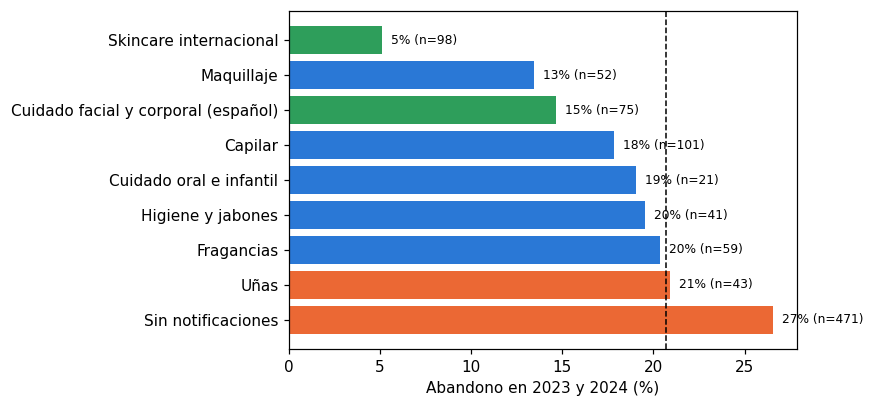

In [ ]:
t = tabla_temas.sort_values("Abandono")
plt.figure(figsize=(8, 3.8))
# verde: los temas que se parecen a Seoru; naranja: por encima del promedio de abandono
colores = [VERDE if "Skincare" in i or "facial" in i else (NARANJA if v > historia[OBJETIVO].mean() else AZUL) for i, v in zip(t.index, t["Abandono"])]
plt.barh(t.index, t["Abandono"] * 100, color=colores)
for i, (v, n) in enumerate(zip(t["Abandono"], t["Importadores-año"])):
    plt.text(v * 100 + 0.5, i, f"{v:.0%} (n={n})", va="center", fontsize=8)
plt.axvline(historia[OBJETIVO].mean() * 100, color="black", ls="--", lw=1)
plt.xlabel("Abandono en 2023 y 2024 (%)"); plt.gca().invert_yaxis()
plt.tight_layout(); plt.savefig(CARPETA_SALIDA + "fig_temas.png", bbox_inches="tight"); plt.show()

**Para Seoru.** Los importadores cuyo portafolio es sobre todo skincare internacional (sérums, cremas, contorno de ojos, SPF) son los que menos abandonan, y además son los que más se parecen a Seoru. Los que no notificaron productos son los que más abandonan. La acción que cambia: la Directora llama primero al grupo de skincare internacional y entra con sérums; con el de cuidado facial en español entra por el protector solar facial. Si se firma con alguien sin notificaciones recientes, el Gerente Financiero le pide la cesión de las NSO como garantía, porque no ha demostrado que sepa manejar trámites sanitarios.

### 8.1 ¿Las variables de texto mejoran el modelo? (y con o sin afinidad, comentario 7 del monitor)

Repetimos la validación anidada con el modelo del radar en tres versiones: la base, la base más los 8 temas (aprendidos dentro de cada pliegue) y la base sin la variable de afinidad.

In [ ]:
version_radar = elegidos[RADAR]["versión"]
modelo_base = CANDIDATOS[version_radar][1].named_steps["modelo"]
variantes = {
    "Base": (RADAR, Pipeline([("preparacion", preparacion()), ("modelo", clone(modelo_base))])),
    "Base + temas de texto": (RADAR, Pipeline([("preparacion", preparacion(con_texto=True)), ("modelo", clone(modelo_base))])),
    "Base sin afinidad": (RADAR, Pipeline([("preparacion", preparacion(sin_afinidad=True)), ("modelo", clone(modelo_base))])),
}
filas = []
for nombre, v in variantes.items():
    r = validacion_anidada({nombre: v}, ent, y_ent, incluir_regla=False)
    filas.append({"Versión": nombre, "Costo medio (US$ M por 100)": r["Costo por 100"].mean() / 1e6,
                  "DE": r["Costo por 100"].std() / 1e6, "AUC medio": r["AUC"].mean()})
prueba_texto = pd.DataFrame(filas).set_index("Versión")
prueba_texto.to_csv(CARPETA_SALIDA + "tabla_prueba_texto.csv")
dif_texto = prueba_texto.loc["Base + temas de texto", "Costo medio (US$ M por 100)"] - prueba_texto.loc["Base", "Costo medio (US$ M por 100)"]
print(f"Cambio en el costo al agregar los temas: {dif_texto:+.3f} M por 100 | desviación entre pliegues de la base: {prueba_texto.loc['Base', 'DE']:.3f} M")
prueba_texto.round(3)

Cambio en el costo al agregar los temas: -0.027 M por 100 | desviación entre pliegues de la base: 0.308 M


,Costo medio (US$ M por 100),DE,AUC medio
Versión,,,
Base,2.662,0.308,0.732
Base + temas de texto,2.634,0.295,0.735
Base sin afinidad,2.718,0.359,0.736


**Qué vemos.** Agregar los temas cambia el costo en unas decenas de miles de dólares por cada 100 importadores y el AUC casi nada. Es unas diez veces menos que lo que varía el costo entre pliegues, así que no es una mejora real: lo que dicen los temas ya está en las 10 categorías y en la afinidad. Por eso el modelo final no usa los temas (además, la app tendría que recibir texto libre). Quitar la afinidad sube un poco el costo, también dentro del ruido; la dejamos porque es fácil de explicar y sirve para ordenar. En resumen, el texto no mejora la predicción, pero sí cambia la decisión, porque dice quién vende lo mismo que Seoru (sección 9.3).

## 9. Despliegue: el radar de 2026
### 9.1 Modelo final con 2023 y 2024, agrupando por NIT

Para puntuar a los importadores de 2025 usamos los dos años con desenlace conocido. Como un mismo importador aparece en 2023 y en 2024, la validación cruzada agrupa por NIT; así el modelo nunca se evalúa con una empresa que ya vio al entrenar. Los pliegues los armamos con una función propia que reparte igual que `GroupKFold`: al correr el cuaderno en Colab vimos que `GroupKFold` desempata distinto según la versión de scikit-learn, y eso movía los umbrales de una máquina a otra. Dentro de la familia del radar volvemos a escoger la versión y los dos umbrales por costo, y la regla también se reajusta con los dos años.

In [ ]:
def pliegues_por_nit(grupos, k=K):
    # mismo reparto que GroupKFold: los NIT con más filas van primero, siempre al pliegue más liviano.
    # Lo hacemos a mano porque GroupKFold desempata distinto según la versión de scikit-learn.
    nits, idx = np.unique(grupos, return_inverse=True)
    filas = np.bincount(idx)
    orden = np.argsort(filas, kind="stable")[::-1]
    peso = np.zeros(k)
    pliegue = np.zeros(len(nits), dtype=int)
    for n in orden:
        f = int(np.argmin(peso))
        peso[f] += filas[n]
        pliegue[n] = f
    return pliegue[idx]

historia = historia.reset_index(drop=True)
y_hist = historia[OBJETIVO].astype(int).values
grupos = historia["nit"].values
gkf = PredefinedSplit(pliegues_por_nit(grupos))   # 5 pliegues; un NIT nunca queda en dos
final = None
for nombre, (familia, est) in CANDIDATOS.items():
    if familia != RADAR:   # solo las versiones de la familia que ganó
        continue
    p = prob_fuera_de_pliegue(est, historia, y_hist, gkf, grupos)
    c, u1, u2 = mejores_umbrales(p, y_hist)
    if final is None or c < final["costo"]:
        final = {"versión": nombre, "costo": c, "u1": u1, "u2": u2, "auc": roc_auc_score(y_hist, p)}
_, A_FINAL, B_FINAL = mejor_regla(historia["n_meses_activos_t"].values, y_hist)
REGLA_FINAL = texto_regla(A_FINAL, B_FINAL)
U1, U2 = final["u1"], final["u2"]
print(f"Versión final: {final['versión']} | umbrales {U1} y {U2} | costo VC agrupada {final['costo'] / 1e6:.2f} M por 100 | AUC {final['auc']:.3f}")
print("Regla reajustada con 2023 y 2024:", REGLA_FINAL)

Versión final: Bosque prof=5 hoja=5 | umbrales 0.17 y 0.22 | costo VC agrupada 2.57 M por 100 | AUC 0.752
Regla reajustada con 2023 y 2024: No firmar si importó menos de 6 meses; garantías si importó 6; firmar desde 7


**Antes de exportar: protección de los datos.** La plantilla guarda en `model/metadata.json` el mínimo, el máximo y la mediana de cada columna de entrada. El mínimo y el máximo serían valores exactos de importación de alguna empresa, y las condiciones de uso de LegisComex no lo permiten. Por eso, solo para el modelo que se publica, recortamos las columnas de LegisComex al percentil 1–99 y las redondeamos a dos cifras significativas. Abajo comprobamos que las probabilidades casi no cambian.

In [ ]:
LEGISCOMEX = ["cif_t", "n_decl_t", "n_proveedores_t", "n_paises_t", "n_meses_activos_t", "share_china_t", "share_ue_t", "share_usa_t",
              "momentum_h2_t", "usd_por_kg_t", "cif_por_mes", "decl_por_mes", "decl_por_proveedor", "intensidad_sanitaria"]
CONTINUAS_LC = ["cif_t", "n_decl_t", "n_proveedores_t", "usd_por_kg_t", "cif_por_mes", "decl_por_mes", "decl_por_proveedor", "intensidad_sanitaria"]
limites = historia[CONTINUAS_LC].quantile([0.01, 0.99])

def redondear(x, cifras=2):
    # redondea a 2 cifras significativas (por ejemplo, 123.456 -> 120.000)
    x = np.asarray(x, dtype=float)
    salida = np.full_like(x, np.nan)
    ok = np.isfinite(x) & (x != 0)
    potencia = np.floor(np.log10(np.abs(x[ok])))
    salida[ok] = np.round(x[ok] / 10 ** (potencia - cifras + 1)) * 10 ** (potencia - cifras + 1)
    salida[np.isfinite(x) & (x == 0)] = 0
    return salida

def proteger(tabla):
    t = tabla.copy()
    for c in CONTINUAS_LC:
        t[c] = redondear(t[c].clip(limites.loc[0.01, c], limites.loc[0.99, c]))
    return t

historia_pub = proteger(historia)
modelo_final = clone(CANDIDATOS[final["versión"]][1]).fit(historia_pub[ENTRADA], y_hist)   # el que se publica
modelo_crudo = clone(CANDIDATOS[final["versión"]][1]).fit(historia[ENTRADA], y_hist)       # solo para comparar
radar_pub = proteger(radar)
p_radar = modelo_final.predict_proba(radar_pub[ENTRADA])[:, 1]
p_crudo = modelo_crudo.predict_proba(radar[ENTRADA])[:, 1]
misma = (decidir(p_radar, U1, U2) == decidir(p_crudo, U1, U2)).mean()
print(f"Diferencia media de probabilidad con y sin protección: {np.abs(p_radar - p_crudo).mean():.4f} | misma decisión: {misma:.1%}")

Diferencia media de probabilidad con y sin protección: 0.0039 | misma decisión: 99.0%


### 9.2 Recomendación para cada importador de 2025

In [ ]:
radar["probabilidad"] = p_radar
radar["recomendacion"] = decidir(p_radar, U1, U2)
radar["decision_regla"] = regla(radar["n_meses_activos_t"], A_FINAL, B_FINAL)
NOMBRE_DECISION = {"firmar": "Firmar", "garantias": "Firmar con garantías", "no_firmar": "No firmar"}
print(radar["recomendacion"].map(NOMBRE_DECISION).value_counts())
cruce = pd.crosstab(radar["recomendacion"].map(NOMBRE_DECISION), radar["decision_regla"].map(NOMBRE_DECISION),
                    rownames=["Radar (modelo)"], colnames=["Regla simple"])
cruce.to_csv(CARPETA_SALIDA + "tabla_radar_vs_regla.csv")
cruce

recomendacion
Firmar                  253
No firmar               224
Firmar con garantías     46
Name: count, dtype: int64


Regla simple,Firmar,Firmar con garantías,No firmar
Radar (modelo),,,
Firmar,223,13,17
Firmar con garantías,13,11,22
No firmar,6,6,212


**Para Seoru.** El radar y la regla coinciden en la gran mayoría de los importadores de 2025 (la diagonal de la tabla). Cuando no coinciden, casi siempre es un importador de pocos meses que el modelo ve con poco riesgo por su escala o su portafolio, o uno constante que el modelo ve riesgoso y manda a garantías. Esos son los casos que vale la pena mirar con más calma.

### 9.3 Los 20 candidatos para diligencia debida

**Quiénes pueden entrar:** los importadores de 2025 que el radar recomienda firmar, con o sin garantías, menos los dueños de marca. En la primera versión de la lista quedaron arriba Procter & Gamble, Unilever, Henkel, Galderma o Yanbal. El modelo tiene razón en que casi no abandonan, pero son filiales de multinacionales o empresas de venta por catálogo que importan sus propias marcas, y no tendrían por qué distribuir una competidora. Este filtro es un criterio de negocio nuestro, no del modelo: los marcamos por razón social con una lista que se puede revisar, siguen apareciendo en el radar como "dueño de marca" y solo dejan de ocupar cupo en la diligencia debida.

**Cómo se ordenan:** con un puntaje que suma tres cosas, cada una pasada a percentil (de 0 a 1) para que queden en la misma escala:

- **Riesgo, 50 %:** menos probabilidad de abandono, más puntos. Pesa más porque el error más caro (US\$250.000) es firmar con quien abandona.
- **Afinidad con Seoru, 30 %:** proporción de productos con sérum, niacinamida, ácido hialurónico, limpiador o protector solar facial. La pide Asuntos Regulatorios: un socio que ya tramita productos parecidos sabe sacar las NSO de Seoru.
- **Tamaño, 20 %:** valor importado. Da capacidad de distribución, pero pesa menos para que la lista no se llene de gigantes.

Para mostrar cómo cambia el orden al combinar riesgo y afinidad (comentario 7 del monitor), comparamos el puntaje combinado con el orden "solo por riesgo".

In [ ]:
PESOS = {"riesgo": 0.5, "afinidad": 0.3, "tamano": 0.2}

def puntaje(tabla, p, pesos=PESOS):
    return (pesos["riesgo"] * pd.Series(-p, index=tabla.index).rank(pct=True)
            + pesos["afinidad"] * tabla["afinidad_seoru"].rank(pct=True)
            + pesos["tamano"] * tabla["cif_t"].rank(pct=True))

# lista de dueños de marca armada a mano revisando las razones sociales (se puede ampliar)
DUENOS_DE_MARCA = re.compile(r"PROCTER|UNILEVER|HENKEL|GALDERMA|GENOMMA|SESDERMA|AMWAY|\bELCA\b|BEL-?STAR|BELCORP|YANBAL|NATURA COSM|L.?OREAL|"
                             r"COLGATE|JOHNSON & JOHNSON|S C JOHNSON|BEIERSDORF|AVON|KIMBERLY|COTY|PUIG|PIERRE FABRE|BAYER|SANOFI|ABBOTT|"
                             r"NESTL|ESTEE|LAUDER|CHANEL|SHISEIDO|REVLON|OMNILIFE|ORIFLAME|MARY KAY|HERBALIFE|NU SKIN|ISDIN|NAOS|RECKITT|"
                             r"HALEON|KENVUE|DUPREE|JAFRA|QUALA|BABARIA", re.I)

def es_dueno_de_marca(nombres):
    return nombres.fillna("").str.contains(DUENOS_DE_MARCA)

radar["dueno_marca"] = es_dueno_de_marca(radar["importador"])
print("Dueños de marca en 2025:", sorted(radar.loc[radar.dueno_marca, "importador"].unique()))
elegibles = radar[(radar["recomendacion"] != "no_firmar") & ~radar["dueno_marca"]].copy()
elegibles["puntaje"] = puntaje(elegibles, elegibles["probabilidad"].values)
elegibles["puesto"] = elegibles["puntaje"].rank(ascending=False, method="first").astype(int)
elegibles["puesto_solo_riesgo"] = elegibles["probabilidad"].rank(method="first").astype(int)
lista20 = elegibles.sort_values("puesto").head(20).copy()
solo_riesgo20 = set(elegibles.nsmallest(20, "probabilidad").index)
print(f"Recomendados para firmar (con o sin garantías): {int((radar.recomendacion != 'no_firmar').sum())} de {len(radar)}; "
      f"de ellos {int(((radar.recomendacion != 'no_firmar') & radar.dueno_marca).sum())} son dueños de marca → elegibles: {len(elegibles)}")
print(f"De los 20 del puntaje combinado, {len(set(lista20.index) & solo_riesgo20)} también estarían en el top 20 'solo por riesgo'.")
print(f"De los 20, {int((lista20['decision_regla'] == 'firmar').sum())} también los aprueba la regla simple sin garantías.")

def rango_cif(v):
    for a, b, txt in [(0, 1e5, "menos de US$100.000"), (1e5, 5e5, "US$100.000 a US$500.000"), (5e5, 2e6, "US$500.000 a US$2 millones"),
                      (2e6, 1e7, "US$2 a US$10 millones"), (1e7, np.inf, "más de US$10 millones")]:
        if a <= v < b:
            return txt
    return "sin dato"

def texto_meses(m):
    # en rangos, igual que en la app: los meses salen de LegisComex y no se muestran exactos
    if m >= 10:
        return "importó casi todo el año (10 a 12 meses)"
    if m >= 7:
        return "importó de 7 a 9 meses"
    if m >= 4:
        return "importó de 4 a 6 meses"
    return "importó de 1 a 3 meses"

def razones_negocio(f):
    partes = [texto_meses(f.n_meses_activos_t), f"tema: {f.tema.lower()}"]
    if f.afinidad_seoru > 0:
        partes.append(f"{f.afinidad_seoru:.0%} de sus productos se parecen a los de Seoru")
    if pd.notna(f.edad_anios_t):
        partes.append(f"{f.edad_anios_t:.0f} años de matrícula")
    return "; ".join(partes)

lista20["Rango de importación"] = lista20["cif_t"].apply(rango_cif)
lista20["Razones"] = lista20.apply(razones_negocio, axis=1)
lista20["Recomendación"] = lista20["recomendacion"].map(NOMBRE_DECISION)
tabla20 = lista20[["puesto", "importador", "probabilidad", "Recomendación", "tema", "afinidad_seoru", "Rango de importación",
                   "puesto_solo_riesgo", "Razones"]].rename(columns={"puesto": "Puesto", "importador": "Importador", "probabilidad": "Prob. abandono",
                                                                     "tema": "Tema", "afinidad_seoru": "Afinidad", "puesto_solo_riesgo": "Puesto solo por riesgo"})
tabla20.to_csv(CARPETA_SALIDA + "lista_20_candidatos.csv", index=False)
tabla20.round(3)

Dueños de marca en 2025: ['AMWAY COLOMBIA', 'BABARIA COLOMBIA S.A.S', 'BAYER S.A.', 'BEIERSDORF S.A.', 'BEL-STAR S.A.', 'COLGATE PALMOLIVE COMPANIA', 'COLOMBIANA KIMBERLY COLPAPEL S.A.S.', 'ELCA COSMeTICOS COLOMBIA S.A.S.', 'GALDERMA DE COLOMBIA S.A.', 'GENOMMA LAB COLOMBIA LTDA', 'HALEON COLOMBIA S.A.S.', 'HENKEL COLOMBIANA S.A S', 'ISDIN COLOMBIA S.A.S.', 'KENVUE COLOMBIA S.A.', 'LOREAL COLOMBIA S.A.S', 'MARY KAY COLOMBIA SAS', 'NAOS COLOMBIA SAS', 'NATURA COSMETICOS LTDA.', 'NU SKIN COLOMBIA, INC.', 'OMNILIFE DE COLOMBIA SOCIEDAD POR ACCIONES SIMPLIFICADA O SU', 'ORIFLAME DE COLOMBIA S.A.', 'PROCTER & GAMBLE COLOMBIA LTDA', 'PUIG COLOMBIA S.A.S.', 'QUALA S.A.', 'RECKITT BENCKISER COLOMBIA S.A.', 'S C JOHNSON & SON COLOMBIANA S A', 'SESDERMA COLOMBIA S.A.', 'UNILEVER ANDINA COLOMBIA LTDA', 'YANBAL DE COLOMBIA S.A.S']
Recomendados para firmar (con o sin garantías): 299 de 523; de ellos 28 son dueños de marca → elegibles: 271
De los 20 del puntaje combinado, 16 también estarían en el t

,Puesto,Importador,Prob. abandono,Recomendación,Tema,Afinidad,Rango de importación,Puesto solo por riesgo,Razones
149,1,MEDIVELIUS FARMACEUTICA S A,0.019,Firmar,Skincare internacional,0.288,US$2 a US$10 millones,8,importó casi todo el año (10 a 12 meses); tema...
27,2,PERCOS S. A.,0.009,Firmar,Cuidado facial y corporal (español),0.120,US$2 a US$10 millones,1,importó casi todo el año (10 a 12 meses); tema...
221,3,COMERCIALIZADORA LYON SAS,0.017,Firmar,Skincare internacional,0.188,US$500.000 a US$2 millones,5,importó casi todo el año (10 a 12 meses); tema...
212,4,MESPRIT S.A.S,0.017,Firmar,Skincare internacional,0.250,US$500.000 a US$2 millones,6,importó de 7 a 9 meses; tema: skincare interna...
142,5,PREBEL S.A. BIC,0.016,Firmar,Skincare internacional,0.040,más de US$10 millones,4,importó casi todo el año (10 a 12 meses); tema...
68,6,SAINT HONORE DE COLOMBIA SAS,0.015,Firmar,Skincare internacional,0.031,US$2 a US$10 millones,2,importó casi todo el año (10 a 12 meses); tema...
290,7,SURAMERICA COMERCIAL S.A.S,0.024,Firmar,Capilar,0.062,más de US$10 millones,13,importó casi todo el año (10 a 12 meses); tema...
278,8,BLUSH-BAR S.A.S,0.016,Firmar,Skincare internacional,0.055,US$2 a US$10 millones,3,importó casi todo el año (10 a 12 meses); tema...
58,9,AIRLAF INTERNACIONAL S.A.S.,0.028,Firmar,Skincare internacional,0.243,US$500.000 a US$2 millones,16,importó casi todo el año (10 a 12 meses); tema...
265,10,DERMA FRANCE S A S,0.032,Firmar,Skincare internacional,0.263,US$500.000 a US$2 millones,22,importó casi todo el año (10 a 12 meses); tema...


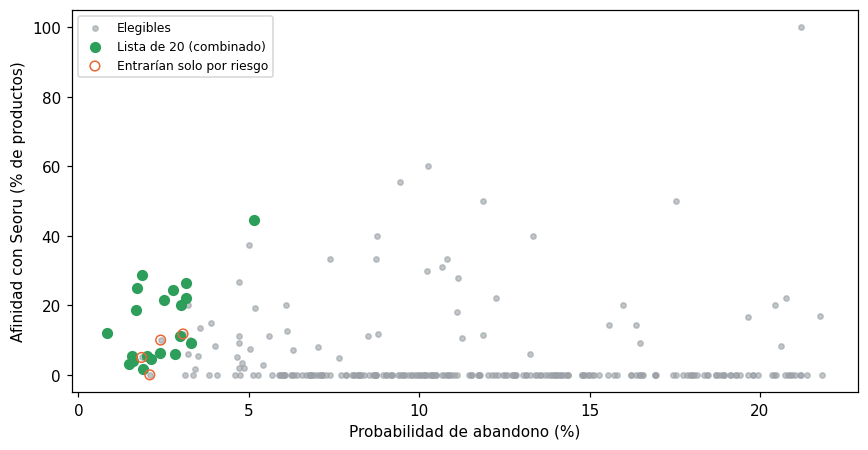

In [ ]:
fig, eje = plt.subplots(figsize=(8, 4.2))
eje.scatter(elegibles["probabilidad"] * 100, elegibles["afinidad_seoru"] * 100, s=12, color=GRIS, alpha=0.6, label="Elegibles")
eje.scatter(lista20["probabilidad"] * 100, lista20["afinidad_seoru"] * 100, s=40, color=VERDE, label="Lista de 20 (combinado)")
sr = elegibles.loc[list(solo_riesgo20 - set(lista20.index))]   # los que entrarían solo por riesgo
eje.scatter(sr["probabilidad"] * 100, sr["afinidad_seoru"] * 100, s=40, facecolors="none", edgecolors=NARANJA, label="Entrarían solo por riesgo")
eje.set_xlabel("Probabilidad de abandono (%)"); eje.set_ylabel("Afinidad con Seoru (% de productos)")
eje.legend(fontsize=8); plt.tight_layout(); plt.savefig(CARPETA_SALIDA + "fig_lista20.png", bbox_inches="tight"); plt.show()

**¿El criterio de orden sirve?** Lo probamos en 2024 con el modelo entrenado solo con 2023: armamos la lista de 20 de 2024 con el mismo criterio y miramos cuántos abandonaron de verdad.

In [ ]:
filtro24 = (decisiones[RADAR] != "no_firmar") & ~es_dueno_de_marca(pru["razon_social"]).values
eleg24 = pru[filtro24].copy()
p24 = puntajes[RADAR][filtro24]
eleg24["puntaje"] = puntaje(eleg24, p24)
comparacion_orden = pd.Series({
    "Todos los elegibles de 2024": eleg24[OBJETIVO].mean(),
    "Top 20: puntaje combinado": eleg24.nlargest(20, "puntaje")[OBJETIVO].mean(),
    "Top 20: solo por riesgo": eleg24.assign(p=p24).nsmallest(20, "p")[OBJETIVO].mean(),
    "Top 20: solo por tamaño": eleg24.nlargest(20, "cif_t")[OBJETIVO].mean(),
    "Top 20: solo por afinidad": eleg24.nlargest(20, "afinidad_seoru")[OBJETIVO].mean(),
}, name="Abandono real en 2025 de la lista de 2024")
comparacion_orden.to_csv(CARPETA_SALIDA + "tabla_orden_2024.csv")
print("Elegibles 2024:", len(eleg24))
# ¿el modelo ordena mejor que los meses dentro de los que la regla aprueba?
aprobados = pru["n_meses_activos_t"].values >= A_REGLA
AUC_DENTRO_MODELO = roc_auc_score(y_pru[aprobados], puntajes[RADAR][aprobados])
AUC_DENTRO_MESES = roc_auc_score(y_pru[aprobados], -pru["n_meses_activos_t"].values[aprobados])
print(f"Dentro de los {aprobados.sum()} que aprueba la regla en 2024 (abandono {y_pru[aprobados].mean():.1%}): "
      f"AUC del modelo {AUC_DENTRO_MODELO:.3f} vs. AUC de los meses solos {AUC_DENTRO_MESES:.3f}")
comparacion_orden.round(3)

Elegibles 2024: 177
Dentro de los 217 que aprueba la regla en 2024 (abandono 8.3%): AUC del modelo 0.679 vs. AUC de los meses solos 0.597


,Abandono real en 2025 de la lista de 2024
Todos los elegibles de 2024,0.09
Top 20: puntaje combinado,0.00
Top 20: solo por riesgo,0.00
Top 20: solo por tamaño,0.00
Top 20: solo por afinidad,0.05


**Para Seoru.** Entre los elegibles de 2024 abandonó el 9 %. En las listas de 20 armadas con el puntaje combinado, solo por riesgo o solo por tamaño no abandonó ninguno, y ordenando solo por afinidad abandonó uno (5 %). O sea, ordenar sí sirve. Además, dentro de los importadores que aprueba la regla, el modelo ordena mejor que los meses solos (los dos AUC de arriba): eso es justo lo que la regla no puede hacer, porque a todos los aprobados los trata igual. El tamaño solo también funcionó en 2024, pero deja por fuera a los que venden lo mismo que Seoru; el puntaje combinado mantiene el riesgo bajo y trae importadores afines. Con 20 empresas, una sola que abandone mueve el porcentaje 5 puntos, así que esto es una señal y no una prueba.

### 9.4 ¿Cuánto vale el radar frente a la regla simple?

Supuestos: (1) los costos del brief; (2) 2025 se parece a 2024, así que usamos la prueba de 2024 con el modelo entrenado en 2023, que es la medición más limpia que tenemos; (3) el valor se mide por cada 100 importadores evaluados, que es la unidad que pide el brief.

In [ ]:
fila_r = tabla_prueba.loc[RADAR]
ahorro = -fila_r["Dif. vs regla"]
dif_boot = boot[RADAR] - boot["Regla simple"]
mejor_trivial = min(tabla_prueba.loc[["Firmar con todos", "Garantías a todos", "No firmar con nadie"], "Costo por 100"])
valor = {"Costo radar (US$ por 100)": fila_r["Costo por 100"],
         "Costo regla (US$ por 100)": tabla_prueba.loc["Regla simple", "Costo por 100"],
         "Ahorro del radar (US$ por 100)": ahorro,
         "IC 95 % ahorro inf": -np.percentile(dif_boot, 97.5), "IC 95 % ahorro sup": -np.percentile(dif_boot, 2.5),
         "Ahorro frente a la mejor decisión trivial (US$ por 100)": mejor_trivial - fila_r["Costo por 100"]}
pd.Series(valor).round(0)

,0
Costo radar (US$ por 100),2871901.0
Costo regla (US$ por 100),2871901.0
Ahorro del radar (US$ por 100),-0.0
IC 95 % ahorro inf,-216942.0
IC 95 % ahorro sup,237862.0
Ahorro frente a la mejor decisión trivial (US$ por 100),1126033.0


**Para Seoru.** El radar ahorra frente a no tener criterio, pero frente a la regla simple el ahorro es cero y su intervalo incluye el cero. Dicho de frente: para decidir si firmar o no, la regla de la constancia basta. Lo que el radar le agrega a Seoru es lo que la regla no da: (1) un orden dentro de los aprobados, que en 2024 llevó a listas de 20 sin abandonos, y (2) las razones de cada recomendación y el encaje por tipo de producto, que pide Asuntos Regulatorios. La aplicación lo dice así.

## 10. Exportar el modelo a la plantilla de la aplicación

La app y el repositorio no llevan la tabla del curso. Exportamos solo el modelo y un archivo de resultados de 2025 con:

- nombre de la empresa (es público en el registro mercantil) y NIT; las personas naturales irían sin nombre ni NIT (en 2025 no queda ninguna en la población);
- probabilidad, recomendación, decisión de la regla, puesto en la lista y razones;
- el valor importado y los meses solo en rangos (por ejemplo, "US\$100.000 a US\$500.000" o "4–6 meses"). Ninguna columna de LegisComex se muestra con su valor exacto, tampoco en las razones (`columnas_ocultas`).

Si no encuentra la carpeta de la app, el cuaderno solo avisa y sigue.

In [ ]:
radar["puesto_lista"] = elegibles["puesto"].reindex(radar.index).fillna(0).astype(int)
radar.loc[radar["puesto_lista"] > 20, "puesto_lista"] = 0
radar["en_lista_20"] = np.where(radar["puesto_lista"] > 0, "Sí", "No")
radar["nit_publico"] = radar["nit"].astype("Int64").astype(str)
radar.loc[radar["nit"].isna(), ["importador", "nit_publico"]] = ["Persona natural (anónima)", "—"]
radar["afinidad_pct"] = (radar["afinidad_seoru"] * 100).round(0)
radar["dueno_marca_txt"] = np.where(radar["dueno_marca"], "Sí", "No")
radar["decision_regla_txt"] = radar["decision_regla"].map(NOMBRE_DECISION)
# la tabla que va a la app parte de la versión protegida (recortada y redondeada)
radar_export = radar_pub.copy()
for c in ["importador", "nit_publico", "tema", "afinidad_pct", "decision_regla_txt", "puesto_lista", "en_lista_20", "dueno_marca_txt"]:
    radar_export[c] = radar[c].values
radar_export["rango_valor"] = radar["cif_t"].apply(rango_cif).values
radar_export["rango_meses"] = tramo_meses(radar["n_meses_activos_t"]).astype(str).values

ETIQUETAS = {"cif_t": "Valor importado", "n_decl_t": "Declaraciones de importación", "n_proveedores_t": "Proveedores",
             "usd_por_kg_t": "Dólares por kilo", "reg_t": "Notificaciones INVIMA nuevas", "reg_t_1": "Notificaciones del año anterior",
             "reg_crec": "Crecimiento de notificaciones", "n_fabricantes_t": "Fabricantes en las notificaciones", "cif_por_mes": "Valor por mes activo",
             "decl_por_mes": "Declaraciones por mes", "decl_por_proveedor": "Declaraciones por proveedor", "intensidad_sanitaria": "Notificaciones por US$1 M",
             "edad_anios_t": "Años de matrícula", "n_paises_t": "Países de origen", "n_meses_activos_t": "Meses con importaciones",
             "share_china_t": "% del valor desde China", "share_ue_t": "% del valor desde la UE", "share_usa_t": "% del valor desde EE. UU.",
             "momentum_h2_t": "% del valor en el segundo semestre", "share_fab_china_t": "% de fabricantes chinos", "share_fab_extranjero_t": "% de fabricantes extranjeros",
             "n_categorias_t": "Categorías de producto", "camara_bogota": "Matrícula en Bogotá", "tiene_productos": "Notificó productos en el año",
             "afinidad_seoru": "Afinidad con Seoru", "forma": "Forma jurídica", "ciiu_letra": "Actividad económica (CIIU)",
             "cat_skincare": "% skincare", "cat_maquillaje": "% maquillaje", "cat_capilar": "% capilar", "cat_fragancia": "% fragancia",
             "cat_corporal": "% corporal", "cat_unas": "% uñas", "cat_solar": "% solar", "cat_oral": "% oral", "cat_desodorante": "% desodorante",
             "cat_hombre": "% hombre", "importador": "Importador", "nit_publico": "NIT", "tema": "Tema de productos", "afinidad_pct": "Afinidad (%)",
             "decision_regla_txt": "Decisión de la regla", "puesto_lista": "Puesto en la lista de 20", "en_lista_20": "En la lista de 20",
             "rango_valor": "Valor importado (rango)", "rango_meses": "Meses con importaciones (rango)", "dueno_marca_txt": "Dueño de marca"}

METRICAS = {
    "costo_modelo": round(float(tabla_prueba.loc[RADAR, "Costo por 100"])),
    "costo_regla": round(float(tabla_prueba.loc["Regla simple", "Costo por 100"])),
    "regla_simple": REGLA_TEXTO,
    "unidad_costo": "en US$ por cada 100 importadores evaluados (prueba 2024, modelo entrenado con 2023)",
    "intervalo_diferencia": [round(float(valor["IC 95 % ahorro inf"])), round(float(valor["IC 95 % ahorro sup"]))],
    "modelo": f"{RADAR}: en la prueba, {elegidos[RADAR]['versión']} entrenado con 2023; en el radar 2026, {final['versión']} entrenado con 2023 y 2024",
    "auc_prueba": round(float(tabla_prueba.loc[RADAR, "AUC"]), 3),
    "costo_no_firmar_con_nadie": round(float(tabla_prueba.loc["No firmar con nadie", "Costo por 100"])),
    "costo_firmar_con_todos": round(float(tabla_prueba.loc["Firmar con todos", "Costo por 100"])),
    "regla_reajustada_2023_2024": REGLA_FINAL,
}
COLUMNAS_A_MOSTRAR = ["nit_publico", "en_lista_20", "puesto_lista", "tema", "afinidad_pct", "rango_valor", "rango_meses", "decision_regla_txt", "dueno_marca_txt"]
OCULTAS = LEGISCOMEX   # sus valores exactos no salen ni en la tabla ni en las razones

carpeta_app = CARPETA_APP
if not os.path.exists(os.path.join(carpeta_app, "exportar.py")) and "google.colab" in sys.modules:
    # por si la carpeta quedó con otro nombre (plantilla_app o glowup_radar_app)
    encontradas = (glob.glob("/content/drive/MyDrive/**/plantilla_app/exportar.py", recursive=True)
                   + glob.glob("/content/drive/MyDrive/**/glowup_radar_app/exportar.py", recursive=True))
    carpeta_app = os.path.dirname(encontradas[0]) if encontradas else carpeta_app
if os.path.exists(os.path.join(carpeta_app, "exportar.py")):
    sys.path.insert(0, carpeta_app)
    from exportar import exportar
    meta = exportar(modelo=modelo_final, X_entrenamiento=historia_pub[ENTRADA], umbrales=[U1, U2] if U2 > U1 else [U1],
                    decisiones=["Firmar", "Firmar con garantías", "No firmar"] if U2 > U1 else ["Firmar", "No firmar"],
                    metricas=METRICAS, evento="abandono", tabla_resultados=radar_export,
                    probabilidad_resultados=p_radar, columna_id="importador", columnas_a_mostrar=COLUMNAS_A_MOSTRAR,
                    etiquetas=ETIQUETAS, columnas_ocultas=OCULTAS)
    # archivos extra que usa nuestra app (comparación, temas y parámetros de la lista)
    tabla_prueba.reset_index().to_csv(os.path.join(carpeta_app, "model", "comparacion_modelos.csv"), index=False)
    tabla_temas.reset_index().drop(columns=["Palabras principales"]).to_csv(os.path.join(carpeta_app, "model", "temas.csv"), index=False)
    with open(os.path.join(carpeta_app, "model", "extra.json"), "w", encoding="utf-8") as f:
        json.dump({"pesos_lista": PESOS, "regla_final": REGLA_FINAL, "a_regla": int(A_FINAL), "b_regla": int(B_FINAL), "u1": U1, "u2": U2,
                   "radar": RADAR, "elegibles": int(len(elegibles)), "n_radar": int(len(radar))}, f, ensure_ascii=False, indent=2)
    print("Exportado a", carpeta_app)
else:
    print("No encontramos la carpeta de la app en", carpeta_app, "→ si quieren exportar, revisen CARPETA_APP en la sección 2.")

No encontramos la carpeta de la app en /content/drive/MyDrive/GlowUp_Radar/plantilla_app → si quieren exportar, revisen CARPETA_APP en la sección 2.


Después de exportar: llenamos `mi_app.py`, adaptamos `app.py` a Seoru y corrimos `check.py` hasta que respondió **LISTO PARA DESPLEGAR**. Al publicar en Streamlit hay que elegir la versión de Python que imprime la celda de arriba.

## 11. Resumen de cifras para el informe

Todas las cifras del informe, el memo y la app salen de esta celda. Si al correr el cuaderno en otro computador cambia alguna, hay que actualizarla allá también.

In [ ]:
cifras = {
    "Filas población 2023/2024/2025": f"{len(ent)}/{len(pru)}/{len(radar)}",
    "Tasa base 2023 / 2024": f"{y_ent.mean():.1%} / {y_pru.mean():.1%}",
    "Regla ajustada 2023": REGLA_TEXTO,
    "Regla reajustada 2023+2024": REGLA_FINAL,
    "Modelo del radar": f"{RADAR} · {elegidos[RADAR]['versión']} (2023) · {final['versión']} (final)",
    "Umbrales 2023 / final": f"{elegidos[RADAR]['u1']}–{elegidos[RADAR]['u2']} / {U1}–{U2}",
}
for m in resumen_anidada.index:
    cifras[f"Anidada · {m}"] = f"{resumen_anidada.loc[m, 'costo_medio'] / 1e6:.2f} M ± {resumen_anidada.loc[m, 'costo_de'] / 1e6:.2f} · AUC {resumen_anidada.loc[m, 'auc_medio']:.3f}"
for m in tabla_prueba.index:
    r = tabla_prueba.loc[m]
    cifras[f"Prueba 2024 · {m}"] = (f"{r['Costo por 100'] / 1e6:.2f} M ({r['IC inf'] / 1e6:.2f}–{r['IC sup'] / 1e6:.2f}) · dif {r['Dif. vs regla'] / 1e6:+.2f} "
                                   f"({r['Dif. IC inf'] / 1e6:+.2f} a {r['Dif. IC sup'] / 1e6:+.2f}) · sens {r['Sensibilidad']:.2f} · prec {r['Precisión']:.2f} · AUC {r['AUC']:.3f}")
cifras["Radar 2025"] = radar["recomendacion"].map(NOMBRE_DECISION).value_counts().to_dict()
cifras["Elegibles 2025 (sin dueños de marca)"] = len(elegibles)
cifras["Dueños de marca recomendados para firmar"] = int(((radar.recomendacion != "no_firmar") & radar.dueno_marca).sum())
cifras["AUC dentro de aprobados 2024: modelo / meses"] = f"{AUC_DENTRO_MODELO:.3f} / {AUC_DENTRO_MESES:.3f}"
cifras["Lista 20 aprobados por la regla"] = int((lista20["decision_regla"] == "firmar").sum())
cifras["Lista 20 que también están solo por riesgo"] = len(set(lista20.index) & solo_riesgo20)
for k, v in comparacion_orden.items():
    cifras[f"Orden 2024 · {k}"] = f"{v:.1%}"
for k, v in prueba_texto.iterrows():
    cifras[f"Texto · {k}"] = f"{v['Costo medio (US$ M por 100)']:.2f} M · AUC {v['AUC medio']:.3f}"
pd.Series(cifras, name="Valor").to_frame()

,Valor
Filas población 2023/2024/2025,477/484/523
Tasa base 2023 / 2024,21.4% / 20.0%
Regla ajustada 2023,No firmar si importó menos de 7 meses; firmar ...
Regla reajustada 2023+2024,No firmar si importó menos de 6 meses; garantí...
Modelo del radar,Bosque aleatorio · Bosque prof=None hoja=20 (2...
Umbrales 2023 / final,0.16–0.16 / 0.17–0.22
Anidada · Regla simple,2.52 M ± 0.48 · AUC 0.744
Anidada · Árbol de decisión,2.60 M ± 0.54 · AUC 0.699
Anidada · Bosque aleatorio,2.77 M ± 0.24 · AUC 0.740
Anidada · XGBoost,2.82 M ± 0.42 · AUC 0.738
